## Step A: Rebuild the Part 1 baseline
These cells are identical to Part 1: setup, data, weekly table, restart detection, Arps and gradient boosting.

In [ ]:
# 0a. Connect Google Drive (click "Allow" when asked)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Not running in Colab - skipping Drive mount.")

Mounted at /content/drive


In [ ]:
# 0b. Paths. Change these only if your folders are named differently.
PROJECT = "/content/drive/MyDrive/volve-forecasting"   # results are saved here
SRC = "/content/drive/MyDrive/petro"                    # this notebook's folder

DATA_FILE_NAME = "Volve production data.xlsx"

# Forecast dates (see "Rules of the test" above)
VAL_START = "2014-10-01"     # practice year starts (week of 29 Sep 2014)
TEST_START = "2015-10-01"    # test year starts (week of 28 Sep 2015)
HORIZON = 52                 # weeks to forecast

In [ ]:
# 0c. Imports, folders and chart style
import glob, math, os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.optimize import curve_fit, OptimizeWarning
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore", category=OptimizeWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

OUT = Path(PROJECT) / "outputs"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

VAL_ORIGIN = pd.Timestamp(VAL_START).to_period("W-SUN").start_time    # a Monday
TEST_ORIGIN = pd.Timestamp(TEST_START).to_period("W-SUN").start_time

COLORS = {"Arps decline": "#C0392B", "Gradient boosting": "#2471A3", "TFT": "#7D3C98"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.savefig(FIG / name, dpi=140, bbox_inches="tight")
    print(f"Saved figure: outputs/figures/{name}")

print("Practice-year forecast date:", VAL_ORIGIN.date())
print("Test-year forecast date:    ", TEST_ORIGIN.date())

Practice-year forecast date: 2014-09-29
Test-year forecast date:     2015-09-28


In [ ]:
# 1a. Find and load the daily production sheet
search = [Path(PROJECT) / "data" / DATA_FILE_NAME, Path(SRC) / DATA_FILE_NAME, Path(PROJECT) / DATA_FILE_NAME]
search += [Path(p) for p in glob.glob(f"{PROJECT}/**/*.xlsx", recursive=True) + glob.glob(f"{SRC}/**/*.xlsx", recursive=True)
           if "volve" in Path(p).name.lower() or "production" in Path(p).name.lower()]
DATA_FILE = next((p for p in search if p.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError(f"Put '{DATA_FILE_NAME}' in {PROJECT}/data/ and run again.")

sheets = pd.ExcelFile(DATA_FILE).sheet_names
sheet = "Daily Production Data" if "Daily Production Data" in sheets else sheets[0]
raw = pd.read_excel(DATA_FILE, sheet_name=sheet)
raw.columns = raw.columns.str.strip().str.upper()
raw["DATEPRD"] = pd.to_datetime(raw["DATEPRD"])
raw = raw.rename(columns={"NPD_WELL_BORE_NAME": "well"})
print(f"Loaded {len(raw):,} daily rows from {DATA_FILE.name} (sheet '{sheet}')")
print(f"Dates: {raw['DATEPRD'].min().date()} to {raw['DATEPRD'].max().date()}")
raw.groupby(["well", "WELL_TYPE"]).size().unstack(fill_value=0)

Loaded 15,634 daily rows from Volve production data.xlsx (sheet 'Daily Production Data')
Dates: 2007-09-01 to 2016-12-01


WELL_TYPE,OP,WI
well,,
15/9-F-1 C,744,2
15/9-F-11,1165,0
15/9-F-12,3056,0
15/9-F-14,3056,0
15/9-F-15 D,978,0
15/9-F-4,0,3327
15/9-F-5,144,3162


In [ ]:
# 2a. Daily -> weekly, per producer
d = raw[raw["WELL_TYPE"] == "OP"].copy()
d["ON_STREAM_HRS"] = d["ON_STREAM_HRS"].clip(0, 24).fillna(0)
for c in ["BORE_OIL_VOL", "BORE_WAT_VOL", "BORE_GAS_VOL"]:
    d[c] = d[c].fillna(0)
d = d[(d["ON_STREAM_HRS"] > 0) & (d["BORE_OIL_VOL"] > 0)]
for c in ["AVG_CHOKE_SIZE_P", "AVG_WHP_P"]:
    d[c] = d[c].where(d[c] > 0)          # zeros are gauge gaps, not real readings
d["week"] = d["DATEPRD"].dt.to_period("W-SUN").dt.start_time

frames = []
for well, g in d.groupby("well"):
    w = g.groupby("week").agg(oil=("BORE_OIL_VOL", "sum"), water=("BORE_WAT_VOL", "sum"),
                              gas=("BORE_GAS_VOL", "sum"), hours=("ON_STREAM_HRS", "sum"),
                              choke=("AVG_CHOKE_SIZE_P", "mean"), whp=("AVG_WHP_P", "mean"))
    w = w.reindex(pd.date_range(w.index.min(), w.index.max(), freq="W-MON"))   # no missing weeks
    w.index.name = "week"
    w["hours"] = w["hours"].fillna(0)
    w[["oil", "water", "gas"]] = w[["oil", "water", "gas"]].fillna(0)
    observed = w["hours"] >= 48                       # at least 2 producing days
    w["rate"] = (w["oil"] / (w["hours"] / 24)).where(observed)
    w["water_cut"] = (w["water"] / (w["water"] + w["oil"])).where(observed)
    w["on_frac"] = w["hours"] / 168
    w["well"] = well
    frames.append(w.reset_index())
weekly = pd.concat(frames, ignore_index=True)
weekly["log_rate"] = np.log(weekly["rate"])

# Filled versions used only as model INPUTS (targets always use the real, unfilled rate)
g = weekly.groupby("well")
weekly["log_rate_f"] = g["log_rate"].transform(lambda s: s.interpolate(limit_direction="both"))
weekly["water_cut_f"] = g["water_cut"].transform(lambda s: s.interpolate(limit_direction="both")).fillna(0)
weekly["choke_f"] = g["choke"].transform(lambda s: s.ffill().bfill())
weekly["whp_f"] = g["whp"].transform(lambda s: s.ffill().bfill())

weekly.to_csv(OUT / "weekly_production.csv", index=False)
summary = weekly.groupby("well").agg(first_week=("week", "min"), last_week=("week", "max"),
                                     weeks=("week", "count"), observed=("rate", "count"),
                                     peak_rate=("rate", "max"))
summary

,first_week,last_week,weeks,observed,peak_rate
well,,,,,
15/9-F-1 C,2014-04-21,2016-04-04,103,69,1215.296667
15/9-F-11,2013-07-22,2016-09-12,165,162,1902.961429
15/9-F-12,2008-02-11,2016-08-08,444,414,5646.580099
15/9-F-14,2008-07-07,2016-07-11,419,398,5215.076391
15/9-F-15 D,2014-01-13,2016-07-04,130,114,461.765000
15/9-F-5,2016-04-18,2016-08-22,19,18,376.975130


In [ ]:
# 2b. Detect rate step-ups (restarts / interventions)
STEP_UP = np.log(1.5)
def detect_events(f):
    lr = f["log_rate"]
    now = lr.rolling(4, min_periods=2).median()
    before = lr.shift(4).rolling(8, min_periods=4).median()
    flag = (now - before) > STEP_UP
    events, last = [], None
    for wk in f.loc[flag, "week"]:
        if last is None or (wk - last).days > 91:      # one event per 13-week cluster
            events.append(wk)
        last = wk
    return events

weekly["event"] = False
event_rows = []
for well, f in weekly.groupby("well"):
    for wk in detect_events(f):
        weekly.loc[(weekly["well"] == well) & (weekly["week"] == wk), "event"] = True
        event_rows.append({"well": well, "week": wk.date()})
g = weekly.groupby("well")
weekly["event_count"] = g["event"].cumsum()
weekly["weeks_since_event"] = 104.0                 # capped at 2 years
for well, f in weekly.groupby("well"):
    since, out = 104, []
    for e in f["event"]:
        since = 0 if e else min(since + 1, 104)
        out.append(since)
    weekly.loc[f.index, "weeks_since_event"] = out
weekly.to_csv(OUT / "weekly_production.csv", index=False)
pd.DataFrame(event_rows)

,well,week
0,15/9-F-1 C,2015-01-05
1,15/9-F-1 C,2015-08-17
2,15/9-F-11,2015-01-19
3,15/9-F-12,2008-05-26
4,15/9-F-12,2008-11-17
5,15/9-F-12,2015-01-05
6,15/9-F-14,2008-09-29
7,15/9-F-14,2009-08-17
8,15/9-F-15 D,2015-08-24


Forecasting: ['15/9-F-1 C', '15/9-F-11', '15/9-F-12', '15/9-F-14', '15/9-F-15 D'] | skipped (too little history): ['15/9-F-5']
Saved figure: outputs/figures/03_backtest_design.png


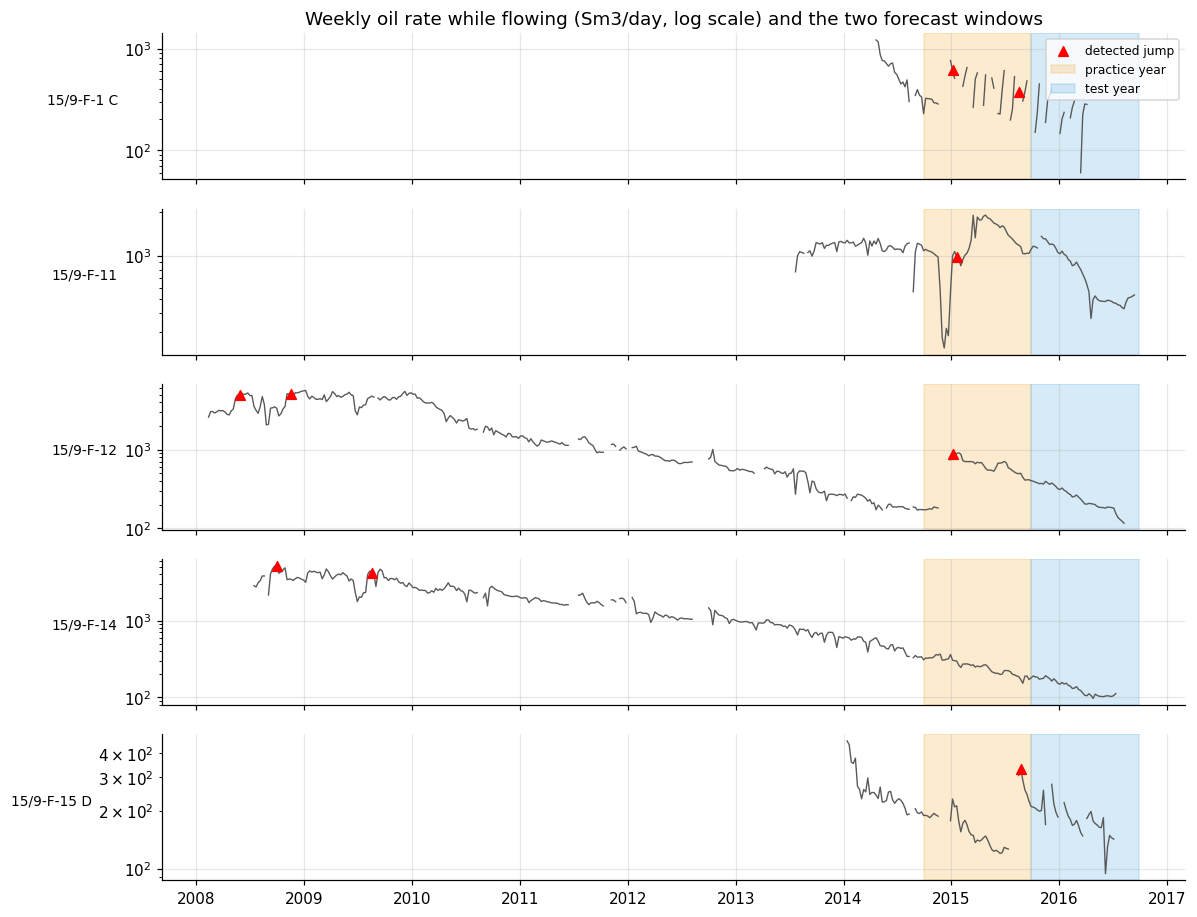

In [ ]:
# 3a. Wells to forecast: producers with at least 26 observed weeks before the test date
obs_before = weekly[weekly["week"] < TEST_ORIGIN].groupby("well")["rate"].count()
wells = sorted(obs_before[obs_before >= 26].index)
print("Forecasting:", wells, "| skipped (too little history):", sorted(set(weekly["well"]) - set(wells)))

# Chart: the two forecast windows on each well's history
fig, axes = plt.subplots(len(wells), 1, figsize=(12, 2.0 * len(wells)), sharex=True)
for ax, well in zip(axes, wells):
    w = weekly[weekly["well"] == well]
    ax.plot(w["week"], w["rate"], color="0.35", lw=0.9)
    ev = w[w["event"]]
    ax.scatter(ev["week"], ev["rate"].fillna(w["rate"].median()), marker="^", color="red", s=40, zorder=3,
               label="detected jump" if well == wells[0] else None)
    ax.axvspan(VAL_ORIGIN, VAL_ORIGIN + pd.Timedelta(weeks=HORIZON), color="#F5B041", alpha=0.25, label="practice year")
    ax.axvspan(TEST_ORIGIN, TEST_ORIGIN + pd.Timedelta(weeks=HORIZON), color="#5DADE2", alpha=0.25, label="test year")
    ax.set_yscale("log"); ax.set_ylabel(well, rotation=0, ha="right", fontsize=9)
axes[0].legend(loc="upper right", fontsize=8)
axes[0].set_title("Weekly oil rate while flowing (Sm3/day, log scale) and the two forecast windows")
save(fig, "03_backtest_design.png"); plt.show()

In [ ]:
# 3b. Helpers shared by every model
def well_arrays(well):
    # One well's weekly series as plain numpy arrays (fast to slice).
    w = weekly[weekly["well"] == well].reset_index(drop=True)
    return {"week": w["week"].values, "lr": w["log_rate"].values, "lr_f": w["log_rate_f"].values,
            "wc": w["water_cut_f"].values, "on": w["on_frac"].values,
            "choke": w["choke_f"].values, "whp": w["whp_f"].values, "rate": w["rate"].values,
            "ev": w["event_count"].values.astype(int), "since": w["weeks_since_event"].values.astype(float)}

def jump_between(a, i, j):
    # True if a detected jump happens after week i and up to week j.
    return a["ev"][j] - a["ev"][i] > 0

def n_before(a, origin):
    # How many weeks of this well come before the forecast date.
    return int((a["week"] < np.datetime64(origin)).sum())

def forecast_frame(well, a, origin_idx, lo, mid, hi, method):
    # Put one well's forecast for the weeks after the origin into a tidy table.
    idx = np.arange(origin_idx + 1, origin_idx + 1 + len(mid))
    return pd.DataFrame({"well": well, "week": a["week"][idx], "h": idx - origin_idx,
                         "actual": a["rate"][idx], "lo": lo, "p50": mid, "hi": hi, "method": method,
                         "after_jump": a["ev"][idx] - a["ev"][origin_idx] > 0})

def future_len(a, i0):
    # Weeks available after origin index i0, capped at the horizon.
    return int(min(HORIZON, len(a["week"]) - (i0 + 1)))

ARRAYS = {w: well_arrays(w) for w in wells}
FORECASTS = {"val": {}, "test": {}}       # filled by Stages 4-6

In [ ]:
# 4a. Arps model
def arps_log(t, qi, di, b):
    return np.log(qi) - np.log1p(b * di * t) / b

def fit_arps(t, y_log):
    qmax = np.exp(y_log.max())
    p0 = [np.exp(np.median(y_log[:4])), 0.01, 0.5]
    bounds = ([0.2 * qmax, 1e-5, 1e-3], [5 * qmax, 0.5, 1.0])
    p0[0] = float(np.clip(p0[0], bounds[0][0] * 1.01, bounds[1][0] * 0.99))
    return curve_fit(arps_log, t, y_log, p0=p0, bounds=bounds, maxfev=20000)[0]

def arps_forecast(origin, n_boot=200, seed=0):
    rng = np.random.default_rng(seed)
    out, params = [], []
    for well, a in ARRAYS.items():
        i0 = n_before(a, origin) - 1
        if i0 < 12 or future_len(a, i0) < 1:
            continue
        hist_t = np.arange(i0 + 1)
        ok = ~np.isnan(a["lr"][: i0 + 1])
        t_obs, y_obs = hist_t[ok], a["lr"][: i0 + 1][ok]
        if len(t_obs) < 13:
            continue
        smooth = pd.Series(y_obs).rolling(5, center=True, min_periods=1).median().values
        recent = t_obs >= i0 - 104                                 # look at the last 2 years only
        start = t_obs[recent][np.argmax(smooth[recent])]           # fit from the smoothed peak in that window
        jumps = np.where(np.diff(a["ev"][: i0 + 1]) > 0)[0] + 1    # week indices of detected jumps
        last_jump = jumps[-1] if len(jumps) else -1
        recent_jump = bool(last_jump > start and (t_obs >= last_jump).sum() < 13)
        if last_jump > start and not recent_jump:
            start = last_jump                                      # 13+ weeks since the jump: fit from it
        sel = t_obs >= start
        if sel.sum() < 13:
            sel = t_obs >= t_obs[-13]
        tf, yf = t_obs[sel] - start, y_obs[sel]
        qi, di, b = fit_arps(tf, yf)
        resid = yf - arps_log(tf, qi, di, b)
        H = future_len(a, i0)
        t_fut = np.arange(i0 + 1, i0 + 1 + H) - start
        sims = []
        for _ in range(n_boot):
            try:
                p = fit_arps(tf, arps_log(tf, qi, di, b) + rng.choice(resid, len(resid)))
            except RuntimeError:
                continue
            sims.append(arps_log(t_fut, *p) + rng.choice(resid, H))
        sims = np.array(sims)
        mid = np.exp(arps_log(t_fut, qi, di, b))
        out.append(forecast_frame(well, a, i0, np.exp(np.percentile(sims, 10, 0)), mid,
                                  np.exp(np.percentile(sims, 90, 0)), "Arps decline"))
        params.append({"well": well, "qi_sm3d": qi, "Di_per_year": di * 52, "b": b, "weeks_fitted": int(sel.sum()),
                       "jump_under_13_weeks_before_forecast": recent_jump})
    return pd.concat(out, ignore_index=True), pd.DataFrame(params)

for run, origin in [("val", VAL_ORIGIN), ("test", TEST_ORIGIN)]:
    FORECASTS[run]["Arps decline"], arps_params = arps_forecast(origin)
print("Arps parameters for the TEST forecast. b near 0 = exponential decline (typical when water cut is rising);")
print("b = 1.0 = harmonic, the upper limit allowed. A b sitting on a limit is worth discussing in your findings.")
arps_params.round(3)

Arps parameters for the TEST forecast. b near 0 = exponential decline (typical when water cut is rising);
b = 1.0 = harmonic, the upper limit allowed. A b sitting on a limit is worth discussing in your findings.


,well,qi_sm3d,Di_per_year,b,weeks_fitted,jump_under_13_weeks_before_forecast
0,15/9-F-1 C,646.656,0.790,1.000,52,True
1,15/9-F-11,1996.392,1.506,0.001,24,False
2,15/9-F-12,831.892,0.864,0.001,37,False
3,15/9-F-14,671.195,0.717,0.001,97,False
4,15/9-F-15 D,302.229,0.665,1.000,78,True


- feature engineering and training

In [ ]:
# 5a. Features and training table
LAGS = 12

def gbm_state(a, i):
    # Describe well `a` at week index i. Returns (features without h, anchor).
    lr = a["lr_f"][i - LAGS + 1: i + 1]
    anchor = lr[-4:].mean()
    wc = a["wc"][i - LAGS + 1: i + 1]
    feats = list((lr[::-1] - anchor))                                   # lag0 .. lag11
    feats += [np.polyfit(np.arange(LAGS), lr, 1)[0],                    # 12-week trend
              wc[-4:].mean(), np.polyfit(np.arange(LAGS), wc, 1)[0],    # water cut level, trend
              np.nanmean(a["on"][i - 3: i + 1]),
              np.nanmean(a["choke"][i - 3: i + 1]) if not np.all(np.isnan(a["choke"][i - 3: i + 1])) else np.nan,
              np.nanmean(a["whp"][i - 3: i + 1]) if not np.all(np.isnan(a["whp"][i - 3: i + 1])) else np.nan,
              a["since"][i]]                                            # weeks since last jump
    return feats, anchor

GBM_COLS = [f"lag{k}" for k in range(LAGS)] + ["trend12", "water_cut", "water_cut_trend",
                                               "on_stream", "choke", "whp", "weeks_since_jump", "horizon"]

def gbm_training_table(origin):
    X, y = [], []
    for well, a in ARRAYS.items():
        n = n_before(a, origin)                       # only weeks before the forecast date
        for i in range(LAGS - 1, n - 1):
            feats, anchor = gbm_state(a, i)
            for h in range(1, HORIZON + 1):
                j = i + h
                if j >= n:
                    break
                if not np.isnan(a["lr"][j]) and not jump_between(a, i, j):   # real week, no jump in between
                    X.append(feats + [h]); y.append(a["lr"][j] - anchor)
    return pd.DataFrame(X, columns=GBM_COLS), np.array(y)

X_demo, y_demo = gbm_training_table(TEST_ORIGIN)
print(f"Test-run training table: {len(X_demo):,} examples x {X_demo.shape[1]} inputs")
X_demo.head()

Test-run training table: 35,183 examples x 20 inputs


,lag0,lag1,lag2,lag3,lag4,lag5,lag6,lag7,lag8,lag9,lag10,lag11,trend12,water_cut,water_cut_trend,on_stream,choke,whp,weeks_since_jump,horizon
0,-0.156064,-0.04813,-0.006113,0.210307,0.192459,0.13748,0.197579,0.258011,0.26357,0.400576,0.69026,0.732895,-0.06921,0.154662,0.020324,0.953001,46.856689,55.200577,104.0,1
1,-0.156064,-0.04813,-0.006113,0.210307,0.192459,0.13748,0.197579,0.258011,0.26357,0.400576,0.69026,0.732895,-0.06921,0.154662,0.020324,0.953001,46.856689,55.200577,104.0,2
2,-0.156064,-0.04813,-0.006113,0.210307,0.192459,0.13748,0.197579,0.258011,0.26357,0.400576,0.69026,0.732895,-0.06921,0.154662,0.020324,0.953001,46.856689,55.200577,104.0,3
3,-0.156064,-0.04813,-0.006113,0.210307,0.192459,0.13748,0.197579,0.258011,0.26357,0.400576,0.69026,0.732895,-0.06921,0.154662,0.020324,0.953001,46.856689,55.200577,104.0,4
4,-0.156064,-0.04813,-0.006113,0.210307,0.192459,0.13748,0.197579,0.258011,0.26357,0.400576,0.69026,0.732895,-0.06921,0.154662,0.020324,0.953001,46.856689,55.200577,104.0,5


In [ ]:
# 5b. Train and forecast
QUANTILES = {"lo": 0.10, "p50": 0.50, "hi": 0.90}

def gbm_forecast(origin, seed=0):
    X, y = gbm_training_table(origin)
    models = {k: HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=400,
                                               learning_rate=0.04, max_leaf_nodes=15,
                                               min_samples_leaf=40, l2_regularization=1.0,
                                               random_state=seed).fit(X, y)
              for k, q in QUANTILES.items()}
    out = []
    for well, a in ARRAYS.items():
        i0 = n_before(a, origin) - 1
        H = future_len(a, i0)
        if i0 < LAGS - 1 or H < 1:
            continue
        feats, anchor = gbm_state(a, i0)
        Xf = pd.DataFrame([feats + [h] for h in range(1, H + 1)], columns=GBM_COLS)
        pred = np.sort(np.vstack([models[k].predict(Xf) for k in ["lo", "p50", "hi"]]), axis=0)
        lo, mid, hi = np.exp(anchor + pred)
        out.append(forecast_frame(well, a, i0, lo, mid, hi, "Gradient boosting"))
    return pd.concat(out, ignore_index=True), models

for run, origin in [("val", VAL_ORIGIN), ("test", TEST_ORIGIN)]:
    t0 = time.time()
    FORECASTS[run]["Gradient boosting"], gbm_models = gbm_forecast(origin)
    print(f"{run}: trained and forecast in {time.time() - t0:.0f}s")

val: trained and forecast in 10s
test: trained and forecast in 13s


In [ ]:
# A-extra. Naive forecast and quantile levels (from Part 1, cell 28)
Q = np.array([0.1, 0.5, 0.9])
def naive_forecast(origin):
    # Simplest possible forecast: hold the last 4-week average rate flat for 52 weeks.
    out = []
    for well, a in ARRAYS.items():
        i0 = n_before(a, origin) - 1
        H = future_len(a, i0)
        if i0 < 3 or H < 1:
            continue
        level = np.full(H, np.exp(a["lr_f"][i0 - 3: i0 + 1].mean()))
        out.append(forecast_frame(well, a, i0, level, level, level, "Naive (flat)"))
    return pd.concat(out, ignore_index=True)
print("Stage A complete.")

Stage A complete.


## Step B: Extra measurements for physics-aware ML

Part 1 used only rates, water cut, choke and wellhead pressure. Volve also records **downhole pressure and temperature, tubing pressure drop, choke pressure drop, wellhead temperature** and **water injection** into F-4 and F-5. This stage adds them to the weekly table, plus two reservoir engineering diagnostics:



In [ ]:
# B1. Weekly means of the extra sensors, per producer
extra = raw[(raw["WELL_TYPE"] == "OP") & (raw["ON_STREAM_HRS"] > 0) & (raw["BORE_OIL_VOL"] > 0)].copy()
for c in ["AVG_DOWNHOLE_PRESSURE", "AVG_DOWNHOLE_TEMPERATURE", "AVG_DP_TUBING", "AVG_WHT_P", "DP_CHOKE_SIZE"]:
    extra[c] = extra[c].where(extra[c] > 0)                    # zeros = dead gauge
extra["week"] = extra["DATEPRD"].dt.to_period("W-SUN").dt.start_time
wk_extra = extra.groupby(["well", "week"]).agg(dhp=("AVG_DOWNHOLE_PRESSURE", "mean"), dht=("AVG_DOWNHOLE_TEMPERATURE", "mean"),
                                               dp_tubing=("AVG_DP_TUBING", "mean"), wht=("AVG_WHT_P", "mean"),
                                               dp_choke=("DP_CHOKE_SIZE", "mean")).reset_index()
weekly = weekly.drop(columns=[c for c in ["dhp", "dht", "dp_tubing", "wht", "dp_choke"] if c in weekly], errors="ignore")
weekly = weekly.merge(wk_extra, on=["well", "week"], how="left")

# B2. Field water injection (F-4 + F-5) and injection ratio
inj = raw[raw["WELL_TYPE"] == "WI"].copy()
inj["week"] = inj["DATEPRD"].dt.to_period("W-SUN").dt.start_time
inj_week = inj.groupby("week")["BORE_WI_VOL"].sum()
prod_week = weekly.groupby("week")[["oil", "water"]].sum().sum(axis=1)
inj_ratio = (inj_week.reindex(prod_week.index).fillna(0) / prod_week.replace(0, np.nan)).rolling(4, min_periods=1).mean()
weekly["inj_ratio"] = weekly["week"].map(inj_ratio).clip(0, 5)

# B3. Water-oil ratio (log) per well, filled for model inputs
weekly["log_wor"] = np.log((weekly["water"] + 1) / (weekly["oil"] + 1)).where(weekly["rate"].notna())
g = weekly.groupby("well")
for c in ["dhp", "dp_tubing", "wht", "dp_choke", "log_wor", "inj_ratio"]:
    weekly[c + "_f"] = g[c].transform(lambda s: s.ffill().bfill())
weekly = weekly.sort_values(["well", "week"]).reset_index(drop=True)
weekly.to_csv(OUT / "weekly_production_plus.csv", index=False)

coverage = weekly[weekly["rate"].notna()].groupby("well")[["dhp", "dp_tubing", "wht", "dp_choke", "log_wor"]].apply(
    lambda d: d.notna().mean() * 100).round(0)
print("Share of producing weeks with a reading (%):")
coverage

Share of producing weeks with a reading (%):


,dhp,dp_tubing,wht,dp_choke,log_wor
well,,,,,
15/9-F-1 C,100.0,100.0,100.0,100.0,100.0
15/9-F-11,100.0,100.0,100.0,100.0,100.0
15/9-F-12,33.0,100.0,100.0,100.0,100.0
15/9-F-14,100.0,100.0,100.0,100.0,100.0
15/9-F-15 D,100.0,100.0,100.0,100.0,100.0
15/9-F-5,0.0,0.0,100.0,100.0,100.0


Saved figure: outputs/figures/20_injection_and_wor.png


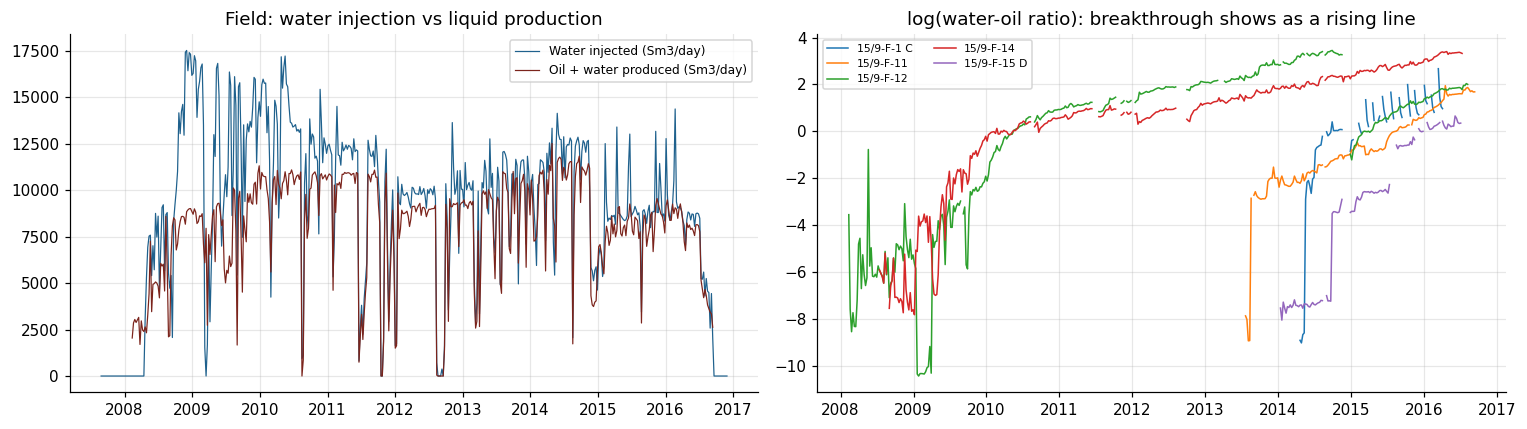

In [ ]:
# B4. Chart: injection support and water-oil ratio
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(inj_week.index, inj_week.values / 7, color="#1F618D", lw=0.8, label="Water injected (Sm3/day)")
axes[0].plot(prod_week.index, prod_week.values / 7, color="#7B241C", lw=0.8, label="Oil + water produced (Sm3/day)")
axes[0].set_title("Field: water injection vs liquid production"); axes[0].legend(fontsize=8)
for well in wells:
    w = weekly[weekly["well"] == well]
    axes[1].plot(w["week"], w["log_wor"], lw=1, label=well)
axes[1].set_title("log(water-oil ratio): breakthrough shows as a rising line"); axes[1].legend(fontsize=7, ncol=2)
fig.tight_layout(); save(fig, "20_injection_and_wor.png"); plt.show()

## Step C: One framework to test every idea the same way

Every model in Part 2 is scored by the **same rolling backtest** as Part 1: 25 forecast dates, one per quarter from Oct 2009 to Sep 2015. Each uses only data before its date. A shared helper builds the training table, so models differ only in their inputs and constraints, and the comparison stays fair.

In [ ]:
# C1. Arrays per well, now with the extra inputs
def well_arrays2(well):
    w = weekly[weekly["well"] == well].reset_index(drop=True)
    a = well_arrays(well)                                  # Part 1 arrays (rates, water cut, choke, jumps...)
    for c in ["dhp_f", "dp_tubing_f", "wht_f", "dp_choke_f", "log_wor_f", "inj_ratio_f"]:
        a[c] = w[c].values.astype(float)
    a["first_week"] = w["week"].iloc[0]
    a["days"] = w["on_frac"].values * 7
    return a

ARRAYS = {w: well_arrays2(w) for w in wells}
ROLL_ORIGINS = sorted(TEST_ORIGIN - pd.Timedelta(weeks=13 * k) for k in range(25))

def slope(v):
    v = np.asarray(v, float)
    ok = ~np.isnan(v)
    return np.polyfit(np.arange(len(v))[ok], v[ok], 1)[0] if ok.sum() >= 3 else np.nan

def m4(v):
    v = np.asarray(v, float)
    return np.nanmean(v) if (~np.isnan(v)).any() else np.nan

# Feature sets. "base" = Part 1 gradient boosting; "physics" adds the Stage B measurements.
def feats_base(a, i):
    f, anchor = gbm_state(a, i)
    return f, anchor

def feats_physics(a, i):
    f, anchor = gbm_state(a, i)
    sl = slice(i - LAGS + 1, i + 1); s4 = slice(i - 3, i + 1)
    f += [m4(a["dhp_f"][s4]), slope(a["dhp_f"][sl]), m4(a["dp_tubing_f"][s4]), m4(a["wht_f"][s4]),
          m4(a["dp_choke_f"][s4]), m4(a["log_wor_f"][s4]), slope(a["log_wor_f"][sl]), m4(a["inj_ratio_f"][s4])]
    return f, anchor

BASE_COLS = GBM_COLS[:-1]                                     # Part 1 columns without "horizon"
PHYS_COLS = BASE_COLS + ["dhp", "dhp_trend", "dp_tubing", "wht", "dp_choke", "log_wor", "log_wor_trend", "inj_ratio"]

def training_table(origin, feat_fn, cols, extra_fn=None, extra_cols=(), stride=1, max_h=HORIZON, exclude=None):
    # Rows = (well, origin week i, horizon h). Target = change in log-rate from the anchor.
    X, y, wl = [], [], []
    for well, a in ARRAYS.items():
        if well == exclude:
            continue
        n = n_before(a, origin)
        for i in range(LAGS - 1, n - 1, stride):
            f, anchor = feat_fn(a, i)
            for h in range(1, max_h + 1):
                j = i + h
                if j >= n:
                    break
                if np.isnan(a["lr"][j]) or jump_between(a, i, j):
                    continue
                ex = list(extra_fn(a, i, j)) if extra_fn else []
                X.append(f + ex + [h]); y.append(a["lr"][j] - anchor); wl.append(well)
    return pd.DataFrame(X, columns=list(cols) + list(extra_cols) + ["horizon"]), np.array(y), np.array(wl)

def fit_quantiles(X, y, monotone=None, quantiles=(0.1, 0.5, 0.9), seed=0):
    cst = None
    if monotone:
        cst = [monotone.get(c, 0) for c in X.columns]
    return [HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=300, learning_rate=0.05,
                                          max_leaf_nodes=15, min_samples_leaf=40, l2_regularization=1.0,
                                          monotonic_cst=cst, random_state=seed).fit(X, y) for q in quantiles]

def ml_forecast(origin, feat_fn, cols, label, monotone=None, extra_fn=None, extra_cols=(), future_extra=None,
                exclude=None, only_well=None, max_h=HORIZON):
    X, y, _ = training_table(origin, feat_fn, cols, extra_fn, extra_cols, exclude=exclude, max_h=max_h)
    models = fit_quantiles(X, y, monotone)
    out = []
    for well, a in ARRAYS.items():
        if only_well and well != only_well:
            continue
        i0 = n_before(a, origin) - 1
        H = min(future_len(a, i0), max_h)
        if i0 < LAGS - 1 or H < 1:
            continue
        f, anchor = feat_fn(a, i0)
        rows = []
        for h in range(1, H + 1):
            ex = list(future_extra(a, i0, i0 + h)) if future_extra else []
            rows.append(f + ex + [h])
        Xf = pd.DataFrame(rows, columns=X.columns)
        pred = np.sort(np.vstack([m.predict(Xf) for m in models]), axis=0)
        lo, mid, hi = np.exp(anchor + pred)
        out.append(forecast_frame(well, a, i0, lo, mid, hi, label))
    return (pd.concat(out, ignore_index=True) if out else pd.DataFrame()), models, X

## Step D: Hybrid models, physics and ML together (recommendation 2)


Why not "ML predicts Arps parameters"? That idea is for forecasting **new** wells from their neighbours' declines. With 5 wells there are too few declines to learn from.

In [ ]:
# D1. Arps fit at any week (same rules as Part 1, no bootstrap) - reused by the correction model
def arps_fit_at(a, i0):
    hist_t = np.arange(i0 + 1)
    ok = ~np.isnan(a["lr"][: i0 + 1])
    t_obs, y_obs = hist_t[ok], a["lr"][: i0 + 1][ok]
    if len(t_obs) < 13:
        return None
    smooth = pd.Series(y_obs).rolling(5, center=True, min_periods=1).median().values
    recent = t_obs >= i0 - 104
    start = t_obs[recent][np.argmax(smooth[recent])]
    jumps = np.where(np.diff(a["ev"][: i0 + 1]) > 0)[0] + 1
    last_jump = jumps[-1] if len(jumps) else -1
    if last_jump > start and (t_obs >= last_jump).sum() >= 13:
        start = last_jump
    sel = t_obs >= start
    if sel.sum() < 13:
        sel = t_obs >= t_obs[-13]
    try:
        qi, di, b = fit_arps(t_obs[sel] - start, y_obs[sel])
    except RuntimeError:
        return None
    return qi, di, b, start

# D2. Arps + ML correction: learn the gap between the Arps curve and what actually happened
CORR_COLS = PHYS_COLS + ["arps_b", "arps_Di", "arps_change"]

def correction_forecast(origin, stride=4):
    X, y = [], []
    for well, a in ARRAYS.items():
        n = n_before(a, origin)
        for i in range(max(LAGS - 1, 26), n - 1, stride):
            fit = arps_fit_at(a, i)
            if fit is None:
                continue
            qi, di, b, start = fit
            f, anchor = feats_physics(a, i)
            for h in range(1, HORIZON + 1):
                j = i + h
                if j >= n:
                    break
                if np.isnan(a["lr"][j]) or jump_between(a, i, j):
                    continue
                arps_j = arps_log(j - start, qi, di, b)
                X.append(f + [b, di * 52, arps_j - anchor, h]); y.append(a["lr"][j] - arps_j)
    X = pd.DataFrame(X, columns=CORR_COLS + ["horizon"]); y = np.array(y)
    models = fit_quantiles(X, y)
    out = []
    for well, a in ARRAYS.items():
        i0 = n_before(a, origin) - 1
        H = future_len(a, i0)
        fit = arps_fit_at(a, i0) if i0 >= LAGS - 1 else None
        if fit is None or H < 1:
            continue
        qi, di, b, start = fit
        f, anchor = feats_physics(a, i0)
        js = np.arange(i0 + 1, i0 + 1 + H)
        arps_js = arps_log(js - start, qi, di, b)
        Xf = pd.DataFrame([f + [b, di * 52, aj - anchor, h] for h, aj in zip(range(1, H + 1), arps_js)], columns=X.columns)
        corr = np.sort(np.vstack([m.predict(Xf) for m in models]), axis=0)
        lo, mid, hi = np.exp(arps_js + corr)
        out.append(forecast_frame(well, a, i0, lo, mid, hi, "Arps + ML correction"))
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()

# D3. Monotonic constraints (-1 = can only push the forecast down as the input grows)
MONOTONE = {"horizon": -1, "water_cut_trend": -1, "log_wor_trend": -1}

def average_forecasts(f1, f2, label):
    # Average two forecasts week by week in log space (averaging quantiles is a standard way to combine forecasts).
    m = f1.merge(f2[["well", "week", "lo", "p50", "hi"]], on=["well", "week"], suffixes=("", "_2"))
    for c in ["lo", "p50", "hi"]:
        m[c] = np.exp((np.log(m[c]) + np.log(m[c + "_2"])) / 2)
    m["method"] = label
    return m[f1.columns]
print("Hybrid model functions ready.")

Hybrid model functions ready.


## Step E: Choke scenarios, treating the choke as a decision (recommendation 3)

Operators *choose* the choke setting, so the useful question is **"what will this well make if we hold the choke at X%?"** This model gets one extra input: the average choke opening planned over the forecast window.



In [ ]:
# E1. Scenario model: future choke plan as an input
def future_choke(a, i, j):
    cur = m4(a["choke"][i - 3: i + 1])
    fut = m4(a["choke"][i + 1: j + 1])
    return [fut - cur if not (np.isnan(fut) or np.isnan(cur)) else np.nan]

def scenario_forecast(origin, delta=None, only_well=None):
    # delta=None -> use the actual future choke (oracle); otherwise a planned change in % points, held flat.
    if delta is None:
        fut_fn = future_choke
    else:
        fut_fn = lambda a, i, j: [float(np.clip(m4(a["choke"][i - 3: i + 1]) + delta, 0, 100)
                                        - m4(a["choke"][i - 3: i + 1]))]
    label = "GB + known choke plan (oracle)" if delta is None else f"choke {delta:+d} pts"
    return ml_forecast(origin, feats_physics, PHYS_COLS, label, extra_fn=future_choke,
                       extra_cols=["choke_plan_change"], future_extra=fut_fn, only_well=only_well)[0]
print("Scenario model ready.")

Scenario model ready.


## Step F: Run the rolling backtest for every model

This runs all models from all 25 forecast dates.

In [ ]:
# F1. Rolling backtest
ROLL = []          # every weekly forecast row from every date and method
t_start = time.time()
for k, origin in enumerate(ROLL_ORIGINS, 1):
    arps = arps_forecast(origin, n_boot=100)[0]
    gb = ml_forecast(origin, feats_base, BASE_COLS, "Gradient boosting")[0]
    gbp = ml_forecast(origin, feats_physics, PHYS_COLS, "GB + physics (monotonic)", monotone=MONOTONE)[0]
    runs = [arps, gb, gbp,
            average_forecasts(arps, gb, "Arps + GB average"),
            correction_forecast(origin),
            scenario_forecast(origin),
            naive_forecast(origin)]
    for df in runs:
        if len(df):
            ROLL.append(df.assign(origin=origin))
    print(f"[{k:2d}/{len(ROLL_ORIGINS)}] {origin.date()} done ({time.time() - t_start:.0f}s)")
ROLL = pd.concat(ROLL, ignore_index=True)
ROLL["days"] = [ARRAYS[w]["days"][np.searchsorted(ARRAYS[w]["week"], np.datetime64(wk))] for w, wk in zip(ROLL["well"], ROLL["week"])]
ROLL.to_csv(OUT / "part2_rolling_forecasts.csv", index=False)
print("Rows:", len(ROLL))

[ 1/25] 2009-10-05 done (16s)
[ 2/25] 2010-01-04 done (34s)
[ 3/25] 2010-04-05 done (53s)
[ 4/25] 2010-07-05 done (75s)
[ 5/25] 2010-10-04 done (97s)
[ 6/25] 2011-01-03 done (121s)
[ 7/25] 2011-04-04 done (147s)
[ 8/25] 2011-07-04 done (171s)
[ 9/25] 2011-10-03 done (198s)
[10/25] 2012-01-02 done (225s)
[11/25] 2012-04-02 done (253s)
[12/25] 2012-07-02 done (282s)
[13/25] 2012-10-01 done (312s)
[14/25] 2012-12-31 done (342s)
[15/25] 2013-04-01 done (374s)
[16/25] 2013-07-01 done (406s)
[17/25] 2013-09-30 done (439s)
[18/25] 2013-12-30 done (475s)
[19/25] 2014-03-31 done (511s)
[20/25] 2014-06-30 done (550s)
[21/25] 2014-09-29 done (591s)
[22/25] 2014-12-29 done (633s)
[23/25] 2015-03-30 done (676s)
[24/25] 2015-06-29 done (721s)
[25/25] 2015-09-28 done (767s)
Rows: 24831


## Step G: Score like an asset team (recommendation 5)
**Volume error:** forecast oil volume vs actual over each forecast window, using the same producing days for both. Planners book volumes, not weekly rates.

Shown:
- Mean log error: a symmetric typical weekly miss.
- Win rate vs Arps: paired, same well and same date.
- A block-bootstrap 95% confidence interval for the difference from Arps.

In [ ]:
# G1. Per (forecast date, well, method) scores
METHOD_ORDER = ["Arps decline", "Gradient boosting", "GB + physics (monotonic)", "Arps + GB average",
                "Arps + ML correction", "GB + known choke plan (oracle)", "Naive (flat)"]
COLORS.update({"GB + physics (monotonic)": "#117A65", "Arps + GB average": "#B9770E",
               "Arps + ML correction": "#6C3483", "GB + known choke plan (oracle)": "#5D6D7E",
               "Naive (flat)": "#909497"})

def score_rows(df):
    df = df[df["actual"].notna() & ~df["after_jump"]]
    rows = []
    for (origin, well, method), g in df.groupby(["origin", "well", "method"]):
        if len(g) < 8:
            continue
        a, p, d = g["actual"].values, g["p50"].values, g["days"].values
        la = np.log(a)
        qs = np.log(np.column_stack([g["lo"], g["p50"], g["hi"]]))
        e = la[:, None] - qs
        rows.append({"origin": origin, "well": well, "method": method,
                     "volume_err_%": ((p * d).sum() - (a * d).sum()) / (a * d).sum() * 100,
                     "log_err": np.mean(np.abs(np.log(p) - la)),
                     "pinball": np.maximum(Q * e, (Q - 1) * e).mean(),
                     "below_p90": np.mean(a < g["lo"]), "below_p50": np.mean(a < g["p50"]),
                     "below_p10": np.mean(a < g["hi"]), "coverage": np.mean((a >= g["lo"]) & (a <= g["hi"]))})
    return pd.DataFrame(rows)

S = score_rows(ROLL)
pairs = S.pivot_table(index=["origin", "well"], columns="method", values="log_err").dropna()
S = S.merge(pairs.reset_index()[["origin", "well"]], on=["origin", "well"])     # same forecasts for every method
METHODS2 = [m for m in METHOD_ORDER if m in S["method"].unique()]

def block_ci(d, n_boot=5000, block=4, seed=0):
    rng = np.random.default_rng(seed)
    by_o = d.groupby(level="origin").mean().sort_index().values
    blocks = [by_o[i:i + block] for i in range(len(by_o) - block + 1)]
    boots = [np.nanmean(np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(by_o) // block + 1)]))
             for _ in range(n_boot)]
    return np.percentile(boots, [2.5, 97.5])

rows = []
for m in METHODS2:
    s = S[S["method"] == m]
    r = {"method": m, "forecasts": len(s), "abs volume error %": s["volume_err_%"].abs().mean(),
         "volume bias %": s["volume_err_%"].mean(), "mean log error": s["log_err"].mean(),
         "pinball": s["pinball"].mean(), "P90-P10 coverage %": s["coverage"].mean() * 100}
    if m != "Arps decline":
        d = pairs[m] - pairs["Arps decline"]
        lo_ci, hi_ci = block_ci(d)
        r.update({"beats Arps %": (d < 0).mean() * 100, "diff vs Arps": d.mean(), "CI low": lo_ci, "CI high": hi_ci,
                  "verdict": "better" if hi_ci < 0 else "worse" if lo_ci > 0 else "no clear difference"})
    rows.append(r)
LEADERBOARD = pd.DataFrame(rows).set_index("method")
LEADERBOARD.round(3).to_csv(OUT / "part2_leaderboard.csv")
print(f"{pairs.shape[0]} paired forecasts per method. Negative 'diff vs Arps' = better than Arps.")
LEADERBOARD.round(2)

64 paired forecasts per method. Negative 'diff vs Arps' = better than Arps.


,forecasts,abs volume error %,volume bias %,mean log error,pinball,P90-P10 coverage %,beats Arps %,diff vs Arps,CI low,CI high,verdict
method,,,,,,,,,,,
Arps decline,64,17.78,6.34,0.22,0.08,53.18,NaN,NaN,NaN,NaN,NaN
Gradient boosting,64,18.98,6.92,0.24,0.09,42.96,40.62,0.02,-0.03,0.05,no clear difference
GB + physics (monotonic),64,16.51,4.40,0.23,0.09,45.68,46.88,0.00,-0.04,0.04,no clear difference
Arps + GB average,64,15.53,5.76,0.21,0.08,54.26,51.56,-0.02,-0.04,0.00,no clear difference
Arps + ML correction,64,18.18,3.09,0.24,0.10,35.92,43.75,0.02,-0.01,0.06,no clear difference
GB + known choke plan (oracle),64,17.10,5.30,0.23,0.09,45.10,48.44,0.00,-0.04,0.03,no clear difference
Naive (flat),64,32.27,31.74,0.33,0.16,0.00,18.75,0.10,0.05,0.13,worse


Saved figure: outputs/figures/21_part2_leaderboard.png


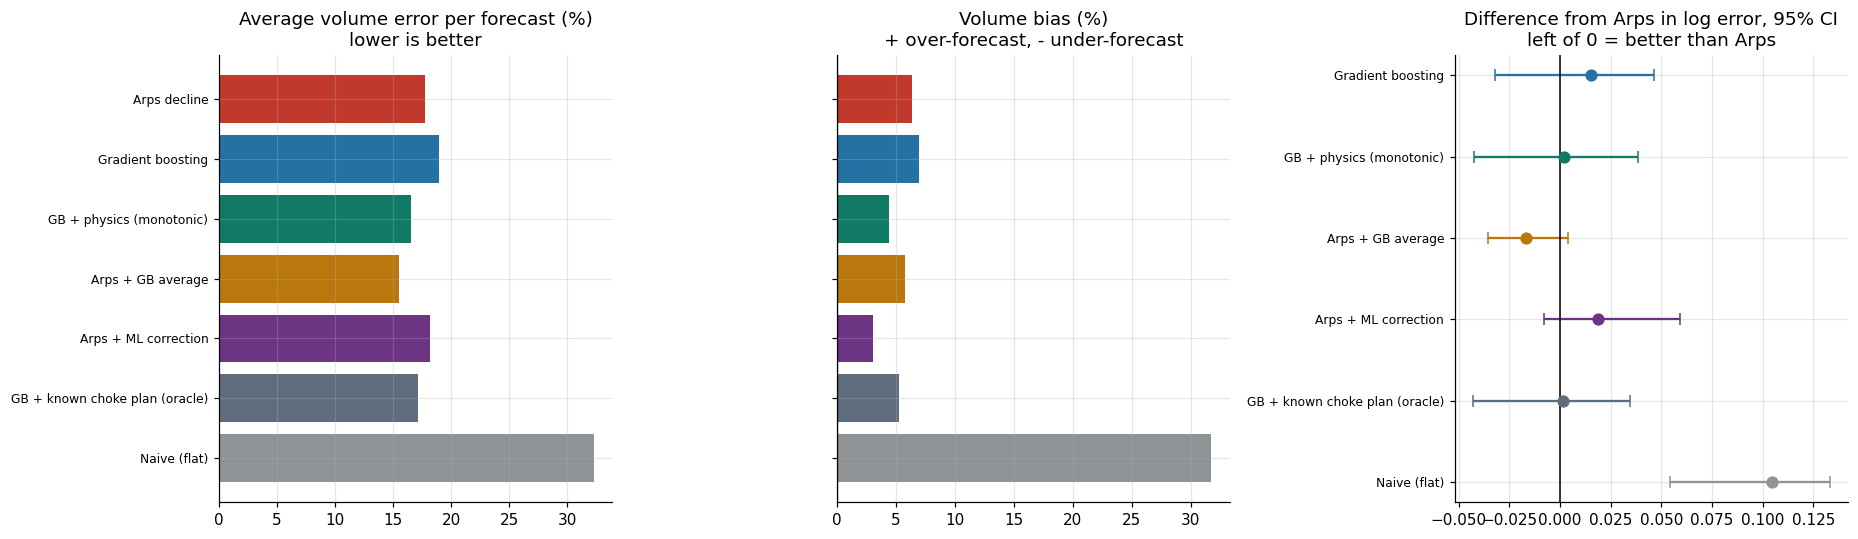

In [ ]:
# G2. Chart: leaderboard
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
lb = LEADERBOARD.loc[METHODS2]
cols = [COLORS[m] for m in METHODS2]
y = np.arange(len(METHODS2))[::-1]
axes[0].barh(y, lb["abs volume error %"], color=cols); axes[0].set_yticks(y, METHODS2, fontsize=8)
axes[0].set_title("Average volume error per forecast (%)\nlower is better")
axes[1].barh(y, lb["volume bias %"], color=cols); axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_yticks(y, [""] * len(y)); axes[1].set_title("Volume bias (%)\n+ over-forecast, - under-forecast")
others = [m for m in METHODS2 if m != "Arps decline"]
for k, m in enumerate(others):
    r = lb.loc[m]; yy = len(others) - 1 - k
    axes[2].errorbar(r["diff vs Arps"], yy, xerr=[[r["diff vs Arps"] - r["CI low"]], [r["CI high"] - r["diff vs Arps"]]],
                     fmt="o", color=COLORS[m], capsize=4, ms=7)
axes[2].set_yticks(range(len(others))[::-1], others, fontsize=8); axes[2].axvline(0, color="k", lw=1)
axes[2].set_title("Difference from Arps in log error, 95% CI\nleft of 0 = better than Arps")
fig.tight_layout(); save(fig, "21_part2_leaderboard.png"); plt.show()

Forecasts per stage: {'Early (< 2 years producing)': 20, 'Mature (2+ years)': 44}
Saved figure: outputs/figures/22_life_stage.png


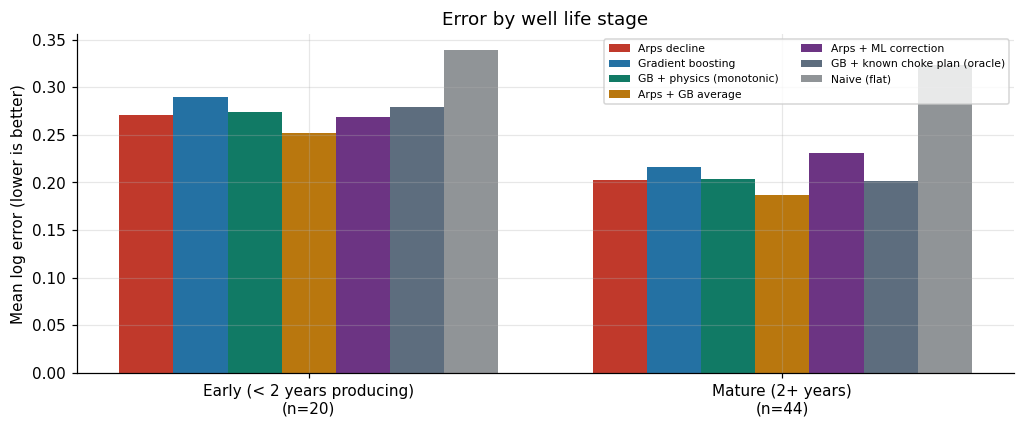

stage,Early (< 2 years producing),Mature (2+ years)
method,,
Arps decline,0.271,0.203
Gradient boosting,0.289,0.217
GB + physics (monotonic),0.274,0.204
Arps + GB average,0.252,0.187
Arps + ML correction,0.269,0.231
GB + known choke plan (oracle),0.279,0.201
Naive (flat),0.339,0.324


In [ ]:
# G3. Life stage: do models behave differently on young and mature wells?
S["years_on"] = [(o - ARRAYS[w]["first_week"]).days / 365.25 for o, w in zip(S["origin"], S["well"])]
S["stage"] = np.where(S["years_on"] < 2, "Early (< 2 years producing)", "Mature (2+ years)")
stage_tbl = S.pivot_table(index="method", columns="stage", values="log_err", aggfunc="mean").loc[METHODS2]
stage_n = S[S["method"] == "Arps decline"].groupby("stage").size()
print("Forecasts per stage:", stage_n.to_dict())
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(stage_tbl.columns)); wdt = 0.8 / len(METHODS2)
for k, m in enumerate(METHODS2):
    ax.bar(x + k * wdt - 0.4 + wdt / 2, stage_tbl.loc[m].values, wdt, color=COLORS[m], label=m)
ax.set_xticks(x, [f"{c}\n(n={stage_n.get(c, 0)})" for c in stage_tbl.columns])
ax.set_ylabel("Mean log error (lower is better)"); ax.legend(fontsize=7, ncol=2)
ax.set_title("Error by well life stage")
save(fig, "22_life_stage.png"); plt.show()
stage_tbl.round(3)

Saved figure: outputs/figures/23_reliability.png


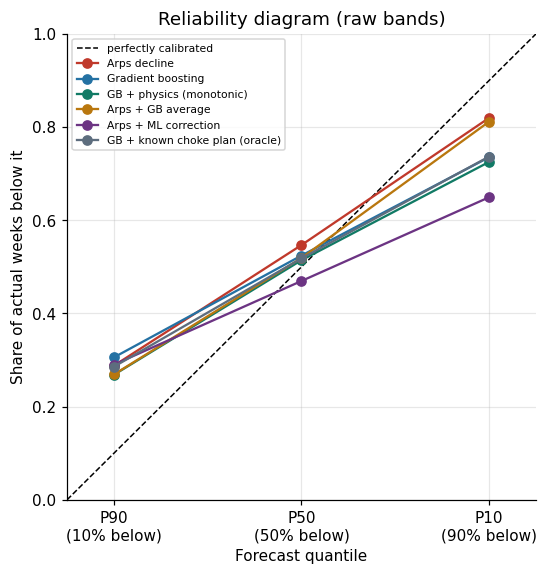

In [ ]:
# G4. Reliability diagram: are the P90 / P50 / P10 honest?
nominal = [0.10, 0.50, 0.90]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="k", ls="--", lw=1, label="perfectly calibrated")
for m in [x for x in METHODS2 if x != "Naive (flat)"]:
    s = S[S["method"] == m]
    obs = [s["below_p90"].mean(), s["below_p50"].mean(), s["below_p10"].mean()]
    ax.plot(nominal, obs, marker="o", color=COLORS[m], label=m)
ax.set_xticks(nominal, ["P90\n(10% below)", "P50\n(50% below)", "P10\n(90% below)"])
ax.set_xlabel("Forecast quantile"); ax.set_ylabel("Share of actual weeks below it")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=7, loc="upper left")
ax.set_title("Reliability diagram (raw bands)")
save(fig, "23_reliability.png"); plt.show()

## Step H: Leave-one-well-out, a well the model has never seen

Train gradient boosting on **four** wells and forecast the **fifth**, at every forecast date. This tells you whether the ML learned something general about Volve wells or only memorised these five. Compare it with:
- the normal model, trained on all wells including the target's own history
- Arps, which by nature only uses the target well

In [ ]:
# H1. Leave-one-well-out backtest (P50 only, for speed)
def ml_point_forecast(origin, exclude, target):
    X, y, _ = training_table(origin, feats_physics, PHYS_COLS, exclude=exclude, stride=2)
    m = HistGradientBoostingRegressor(loss="quantile", quantile=0.5, max_iter=300, learning_rate=0.05,
                                      max_leaf_nodes=15, min_samples_leaf=40, l2_regularization=1.0,
                                      monotonic_cst=[MONOTONE.get(c, 0) for c in X.columns], random_state=0).fit(X, y)
    a = ARRAYS[target]; i0 = n_before(a, origin) - 1; H = future_len(a, i0)
    if i0 < LAGS - 1 or H < 1:
        return None
    f, anchor = feats_physics(a, i0)
    p = np.exp(anchor + m.predict(pd.DataFrame([f + [h] for h in range(1, H + 1)], columns=X.columns)))
    return forecast_frame(target, a, i0, p, p, p, "GB + physics, unseen well")

LOWO = []
t_start = time.time()
for k, origin in enumerate(ROLL_ORIGINS, 1):
    for well in wells:
        f = ml_point_forecast(origin, exclude=well, target=well)
        if f is not None:
            LOWO.append(f.assign(origin=origin))
    print(f"[{k:2d}/{len(ROLL_ORIGINS)}] {origin.date()} ({time.time() - t_start:.0f}s)")
LOWO = pd.concat(LOWO, ignore_index=True)
LOWO["days"] = [ARRAYS[w]["days"][np.searchsorted(ARRAYS[w]["week"], np.datetime64(wk))] for w, wk in zip(LOWO["well"], LOWO["week"])]
S_lowo = score_rows(LOWO)
cmp = (pd.concat([S[S["method"].isin(["Arps decline", "GB + physics (monotonic)"])], S_lowo])
         .pivot_table(index=["origin", "well"], columns="method", values="log_err").dropna())
print(f"{len(cmp)} paired forecasts")
print(cmp.mean().round(3).to_string())
lowo_by_well = cmp.groupby(level="well").mean().round(3)
lowo_by_well

[ 1/25] 2009-10-05 (5s)
[ 2/25] 2010-01-04 (11s)
[ 3/25] 2010-04-05 (17s)
[ 4/25] 2010-07-05 (24s)
[ 5/25] 2010-10-04 (32s)
[ 6/25] 2011-01-03 (40s)
[ 7/25] 2011-04-04 (48s)
[ 8/25] 2011-07-04 (58s)
[ 9/25] 2011-10-03 (66s)
[10/25] 2012-01-02 (76s)
[11/25] 2012-04-02 (86s)
[12/25] 2012-07-02 (94s)
[13/25] 2012-10-01 (105s)
[14/25] 2012-12-31 (116s)
[15/25] 2013-04-01 (127s)
[16/25] 2013-07-01 (138s)
[17/25] 2013-09-30 (149s)
[18/25] 2013-12-30 (161s)
[19/25] 2014-03-31 (173s)
[20/25] 2014-06-30 (185s)
[21/25] 2014-09-29 (198s)
[22/25] 2014-12-29 (212s)
[23/25] 2015-03-30 (226s)
[24/25] 2015-06-29 (240s)
[25/25] 2015-09-28 (254s)
64 paired forecasts
method
Arps decline                 0.224
GB + physics (monotonic)     0.226
GB + physics, unseen well    0.230


method,Arps decline,GB + physics (monotonic),"GB + physics, unseen well"
well,,,
15/9-F-1 C,0.329,0.299,0.317
15/9-F-11,0.290,0.337,0.357
15/9-F-12,0.276,0.257,0.230
15/9-F-14,0.148,0.174,0.195
15/9-F-15 D,0.195,0.135,0.175


Saved figure: outputs/figures/24_leave_one_well_out.png


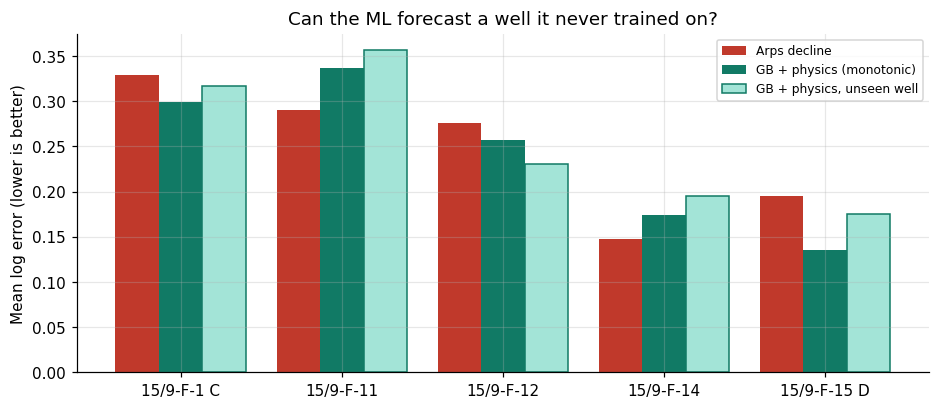

In [ ]:
# H2. Chart: leave-one-well-out by well
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(lowo_by_well)); cols3 = ["Arps decline", "GB + physics (monotonic)", "GB + physics, unseen well"]
COLORS["GB + physics, unseen well"] = "#A3E4D7"
for k, m in enumerate(cols3):
    ax.bar(x + (k - 1) * 0.27, lowo_by_well[m].values, 0.27, color=COLORS[m], label=m,
           edgecolor="#117A65" if "unseen" in m else None)
ax.set_xticks(x, lowo_by_well.index); ax.set_ylabel("Mean log error (lower is better)")
ax.set_title("Can the ML forecast a well it never trained on?"); ax.legend(fontsize=8)
save(fig, "24_leave_one_well_out.png"); plt.show()

## Staep I: Short-horizon forecasting, 1–4 weeks ahead (recommendation 1)

Weekly production planning needs the next month, not the next year. Recent operating conditions dominate at this range. This is a dedicated test with a forecast **every 4 weeks** from 2012 to 2016, about 50 dates per well, scored on the next 4 weeks' oil volume.

In [25]:
# I1. Short-horizon backtest
SHORT_ORIGINS = list(pd.date_range("2012-01-02", "2016-06-27", freq="4W-MON"))
SH = []
t_start = time.time()
for k, origin in enumerate(SHORT_ORIGINS, 1):
    arps = arps_forecast(origin, n_boot=20)[0]
    gbs = ml_forecast(origin, feats_physics, PHYS_COLS, "GB + physics (4-week model)", monotone=MONOTONE, max_h=4)[0]
    nv = naive_forecast(origin)
    for df in [arps, gbs, nv]:
        if len(df):
            SH.append(df[df["h"] <= 4].assign(origin=origin))
    if k % 10 == 0:
        print(f"[{k}/{len(SHORT_ORIGINS)}] ({time.time() - t_start:.0f}s)")
SH = pd.concat(SH, ignore_index=True)
SH["days"] = [ARRAYS[w]["days"][np.searchsorted(ARRAYS[w]["week"], np.datetime64(wk))] for w, wk in zip(SH["well"], SH["week"])]
ok = SH[SH["actual"].notna() & ~SH["after_jump"]]
vol = ok.assign(fv=ok["p50"] * ok["days"], av=ok["actual"] * ok["days"]).groupby(["origin", "well", "method"])[["fv", "av"]].sum()
vol["abs_err_%"] = (vol["fv"] - vol["av"]).abs() / vol["av"] * 100
vt = vol["abs_err_%"].unstack("method").dropna()
short_tbl = pd.DataFrame({"median 4-week volume error %": vt.median(), "mean 4-week volume error %": vt.mean(),
                          "beats Arps %": [(vt[m] < vt["Arps decline"]).mean() * 100 for m in vt.columns]})
print(f"{len(vt)} paired 4-week forecasts")
short_tbl.round(1)

[10/59] (48s)
[20/59] (99s)
[30/59] (152s)
[40/59] (212s)
[50/59] (274s)
198 paired 4-week forecasts


,median 4-week volume error %,mean 4-week volume error %,beats Arps %
method,,,
Arps decline,9.0,14.9,0.0
GB + physics (4-week model),5.7,9.8,67.7
Naive (flat),7.6,11.6,58.1


Saved figure: outputs/figures/25_short_horizon.png


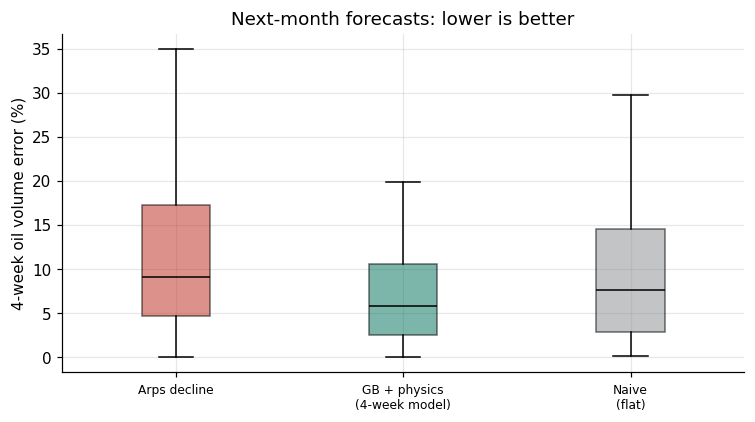

In [26]:
# I2. Chart: short-horizon error distribution
COLORS["GB + physics (4-week model)"] = "#117A65"
fig, ax = plt.subplots(figsize=(8, 4))
ms = list(vt.columns)
bp = ax.boxplot([vt[m].values for m in ms], patch_artist=True, showfliers=False, medianprops=dict(color="black"))
for p_, m in zip(bp["boxes"], ms):
    p_.set_facecolor(COLORS[m]); p_.set_alpha(0.55)
ax.set_xticks(range(1, len(ms) + 1), [m.replace(" (", "\n(") for m in ms], fontsize=8)
ax.set_ylabel("4-week oil volume error (%)"); ax.set_title("Next-month forecasts: lower is better")
save(fig, "25_short_horizon.png"); plt.show()

## Stage J: Water-cut forecasting (recommendation 1)

Water breakthrough caused most of the big oil-rate misses. Forecasting **water cut** directly tells the asset team when to expect water-handling limits, and why oil will fall.



The score is the mean absolute error in **water-cut percentage points** over the next 52 weeks.

In [27]:
# J1. Water-cut models and rolling backtest
def logit(p):
    p = np.clip(p, 0.01, 0.99)
    return np.log(p / (1 - p))
def inv_logit(z):
    return 1 / (1 + np.exp(-z))

def wc_feats(a, i):
    f, _ = feats_physics(a, i)
    lw = logit(a["wc"][i - LAGS + 1: i + 1])
    anchor = lw[-4:].mean()
    return f + list(lw[::-1] - anchor) + [anchor, slope(lw)], anchor
WC_COLS = PHYS_COLS + [f"wc_lag{k}" for k in range(LAGS)] + ["wc_level", "wc_trend"]

def wc_forecasts(origin):
    X, y = [], []
    for well, a in ARRAYS.items():
        n = n_before(a, origin)
        for i in range(LAGS - 1, n - 1, 2):
            f, anchor = wc_feats(a, i)
            for h in range(1, HORIZON + 1, 2):
                j = i + h
                if j >= n:
                    break
                if np.isnan(a["lr"][j]) or jump_between(a, i, j):
                    continue
                X.append(f + [h]); y.append(logit(a["wc"][j]) - anchor)
    X = pd.DataFrame(X, columns=WC_COLS + ["horizon"])
    model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=40, l2_regularization=1.0, random_state=0).fit(X, np.array(y))
    out = []
    for well, a in ARRAYS.items():
        n = n_before(a, origin); i0 = n - 1; H = future_len(a, i0)
        if i0 < 52 or H < 1:
            continue
        f, anchor = wc_feats(a, i0)
        js = np.arange(i0 + 1, i0 + 1 + H)
        ml = inv_logit(anchor + model.predict(pd.DataFrame([f + [h] for h in range(1, H + 1)], columns=X.columns)))
        lw = logit(a["wc"][i0 - 51: i0 + 1]); obs = ~np.isnan(a["lr"][i0 - 51: i0 + 1])
        b1, b0 = np.polyfit(np.arange(52)[obs], lw[obs], 1)
        trend = inv_logit(b0 + b1 * (51 + np.arange(1, H + 1)))
        actual = np.where(np.isnan(a["lr"][js]) | (a["ev"][js] - a["ev"][i0] > 0), np.nan, a["wc"][js])
        for lbl, p in [("Gradient boosting", ml), ("Trend (logit line)", trend), ("Naive (flat)", np.full(H, inv_logit(anchor)))]:
            out.append(pd.DataFrame({"origin": origin, "well": well, "week": a["week"][js], "h": js - i0,
                                     "actual_wc": actual, "pred_wc": p, "method": lbl}))
    return pd.concat(out, ignore_index=True)

WC = pd.concat([wc_forecasts(o) for o in ROLL_ORIGINS], ignore_index=True)
WC = WC[WC["actual_wc"].notna()]
wc_err = (WC.assign(err=(WC["pred_wc"] - WC["actual_wc"]).abs() * 100)
            .groupby(["origin", "well", "method"])["err"].mean().unstack("method").dropna())
wc_tbl = pd.DataFrame({"mean abs error (wc points)": wc_err.mean(), "median": wc_err.median(),
                       "beats trend %": [(wc_err[m] < wc_err["Trend (logit line)"]).mean() * 100 for m in wc_err.columns]})
print(f"{len(wc_err)} paired water-cut forecasts")
wc_tbl.round(1)

60 paired water-cut forecasts


,mean abs error (wc points),median,beats trend %
method,,,
Gradient boosting,7.3,4.6,63.3
Naive (flat),9.2,5.0,41.7
Trend (logit line),11.3,4.9,0.0


Saved figure: outputs/figures/26_water_cut.png


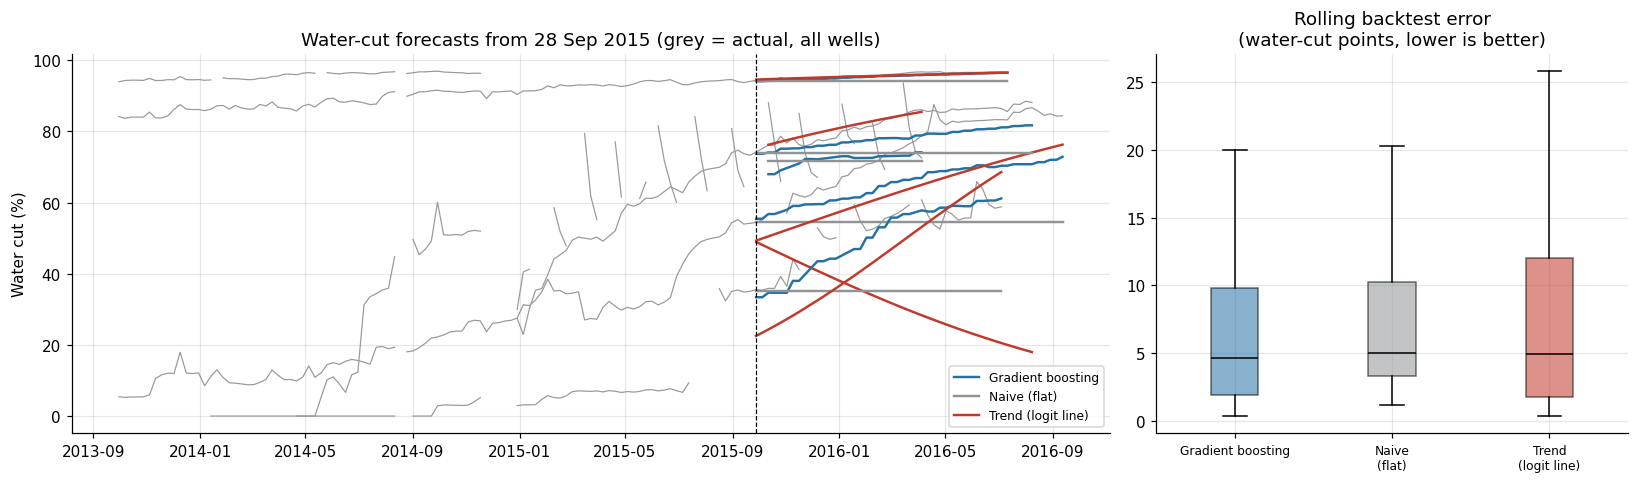

In [28]:
# J2. Chart: water-cut forecasts for the test year, and error comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
wc_cols = {"Gradient boosting": "#2471A3", "Trend (logit line)": "#C0392B", "Naive (flat)": "#909497"}
last = WC[WC["origin"] == TEST_ORIGIN]
for well in wells:
    w = weekly[(weekly["well"] == well) & (weekly["week"] >= TEST_ORIGIN - pd.Timedelta(weeks=104))]
    l, = axes[0].plot(w["week"], w["water_cut"] * 100, lw=0.8, color="0.6")
for (well, method), g in last.groupby(["well", "method"]):
    axes[0].plot(g["week"], g["pred_wc"] * 100, color=wc_cols[method], lw=1.6,
                 label=method if well == wells[0] else None)
axes[0].axvline(TEST_ORIGIN, color="k", ls="--", lw=0.8)
axes[0].set_ylabel("Water cut (%)"); axes[0].set_title("Water-cut forecasts from 28 Sep 2015 (grey = actual, all wells)")
axes[0].legend(fontsize=8)
ms = list(wc_err.columns)
bp = axes[1].boxplot([wc_err[m].values for m in ms], patch_artist=True, showfliers=False, medianprops=dict(color="black"))
for p_, m in zip(bp["boxes"], ms):
    p_.set_facecolor(wc_cols[m]); p_.set_alpha(0.55)
axes[1].set_xticks(range(1, len(ms) + 1), [m.replace(" (", "\n(") for m in ms], fontsize=8)
axes[1].set_title("Rolling backtest error\n(water-cut points, lower is better)")
fig.tight_layout(); save(fig, "26_water_cut.png"); plt.show()

## Step K: Virtual flow meter, ML where it should win (recommendation 1)

A virtual flow meter (VFM) estimates a well's flow rate *today* from its sensors, with no separator test. It checks or replaces expensive multiphase meters.

- Inputs: downhole pressure and temperature, tubing ΔP, choke opening, choke ΔP, wellhead pressure and temperature, hours on stream.
- Targets: daily liquid rate (oil + water) and oil rate.


**Baselines:**
- *Choke equation*: flow ∝ choke area × √(choke ΔP), fitted per well. The classic physics correlation.
- *Stale well test*: the last month's average rate held flat, which is what you have without a meter.

In [29]:
# K1. Daily VFM dataset
vf = raw[(raw["WELL_TYPE"] == "OP") & (raw["ON_STREAM_HRS"] >= 12) & (raw["BORE_OIL_VOL"] > 0) & raw["well"].isin(wells)].copy()
for c in ["AVG_DOWNHOLE_PRESSURE", "AVG_DOWNHOLE_TEMPERATURE", "AVG_DP_TUBING", "AVG_CHOKE_SIZE_P",
          "DP_CHOKE_SIZE", "AVG_WHP_P", "AVG_WHT_P"]:
    vf[c] = vf[c].where(vf[c] > 0)
vf = vf[vf["AVG_CHOKE_SIZE_P"].notna() & vf["DP_CHOKE_SIZE"].notna()]
vf["liquid_rate"] = (vf["BORE_OIL_VOL"] + vf["BORE_WAT_VOL"].fillna(0)) / (vf["ON_STREAM_HRS"] / 24)
vf["oil_rate"] = vf["BORE_OIL_VOL"] / (vf["ON_STREAM_HRS"] / 24)
SENSORS = ["AVG_DOWNHOLE_PRESSURE", "AVG_DOWNHOLE_TEMPERATURE", "AVG_DP_TUBING", "AVG_CHOKE_SIZE_P",
           "DP_CHOKE_SIZE", "AVG_WHP_P", "AVG_WHT_P", "ON_STREAM_HRS"]
vf["choke_term"] = np.log(vf["AVG_CHOKE_SIZE_P"]) + 0.5 * np.log(vf["DP_CHOKE_SIZE"])   # log(area x sqrt(dP))
vf = vf.sort_values(["well", "DATEPRD"]).reset_index(drop=True)
print(f"{len(vf):,} well-days with sensor data | wells: {sorted(vf['well'].unique())}")

def vfm_scores(y, p):
    return {"WAPE %": np.abs(p - y).sum() / y.sum() * 100,
            "median abs error %": np.median(np.abs(p - y) / y) * 100,
            "R2 (log)": 1 - np.sum((np.log(p) - np.log(y)) ** 2) / np.sum((np.log(y) - np.log(y).mean()) ** 2)}

def gbm_vfm():
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                         min_samples_leaf=30, l2_regularization=1.0, random_state=0)

from sklearn.linear_model import LinearRegression
VFM_RESULTS, VFM_PRED = [], {}
for target in ["liquid_rate", "oil_rate"]:
    tr, te = vf[vf["DATEPRD"] < TEST_ORIGIN], vf[vf["DATEPRD"] >= TEST_ORIGIN]
    y_te = te[target].values
    # ML, time split
    p_ml = np.exp(gbm_vfm().fit(tr[SENSORS], np.log(tr[target])).predict(te[SENSORS]))
    # Choke equation per well, time split
    p_ch = np.full(len(te), np.nan)
    for well in te["well"].unique():
        a_, b_ = tr[tr["well"] == well], te["well"].values == well
        if len(a_) > 30:
            lr_ = LinearRegression().fit(a_[["choke_term"]], np.log(a_[target]))
            p_ch[b_] = np.exp(lr_.predict(te.loc[b_, ["choke_term"]]))
    # Stale well test: last 30 producing days before the split, per well
    last30 = tr.groupby("well").tail(30).groupby("well")[target].mean()
    p_st = te["well"].map(last30).values
    for name, p in [("Gradient boosting VFM", p_ml), ("Choke equation", p_ch), ("Stale well test", p_st)]:
        ok_ = ~np.isnan(p)
        VFM_RESULTS.append({"target": target, "test": "time split", "method": name, **vfm_scores(y_te[ok_], p[ok_])})
    VFM_PRED[target] = te.assign(ml=p_ml, choke=p_ch, stale=p_st)
    # Leave-one-well-out (ML vs choke equation fitted on the other wells)
    p_lo, p_lc, y_lo = [], [], []
    for well in wells:
        a_, b_ = vf[vf["well"] != well], vf[vf["well"] == well]
        if len(b_) < 30:
            continue
        p_lo.append(np.exp(gbm_vfm().fit(a_[SENSORS], np.log(a_[target])).predict(b_[SENSORS])))
        p_lc.append(np.exp(LinearRegression().fit(a_[["choke_term"]], np.log(a_[target])).predict(b_[["choke_term"]])))
        y_lo.append(b_[target].values)
    y_lo = np.concatenate(y_lo)
    for name, p in [("Gradient boosting VFM", np.concatenate(p_lo)), ("Choke equation", np.concatenate(p_lc))]:
        VFM_RESULTS.append({"target": target, "test": "unseen well", "method": name, **vfm_scores(y_lo, p)})
VFM_TBL = pd.DataFrame(VFM_RESULTS).set_index(["target", "test", "method"])
VFM_TBL.round(2).to_csv(OUT / "part2_vfm_scores.csv")
VFM_TBL.round(2)

7,609 well-days with sensor data | wells: ['15/9-F-1 C', '15/9-F-11', '15/9-F-12', '15/9-F-14', '15/9-F-15 D']


WAPE %  median abs error %  \
target      test        method                                              
liquid_rate time split  Gradient boosting VFM   17.01               14.15   
                        Choke equation          41.28               41.26   
                        Stale well test         17.41               13.95   
            unseen well Gradient boosting VFM   21.51               18.20   
                        Choke equation          37.11               35.93   
oil_rate    time split  Gradient boosting VFM   61.80               66.13   
                        Choke equation         233.25               74.26   
                        Stale well test         45.94               44.90   
            unseen well Gradient boosting VFM   40.76               43.40   
                        Choke equation          62.56               62.01   

                                               R2 (log)  
target      test        method                           
liquid_rate time split  Gradient boosting VFM      0.91  
                        Choke equation             0.68  
                        Stale well test            0.92  
            unseen well Gradient boosting VFM      0.77  
                        Choke equation             0.53  
oil_rate    time split  Gradient boosting VFM      0.07  
                        Choke equation            -1.28  
                        Stale well test            0.46  
            unseen well Gradient boosting VFM      0.60  
                        Choke equation             0.27

### Step K1b. The realistic test: both methods get a monthly well test

In the field, a VFM is recalibrated against periodic well tests (the well flows through the test separator for a day or so). The fair comparison gives both methods the same monthly test:
- Well test, held: each month's test rate is held flat until the next test, which is what operators have without a VFM.
- GB VFM + monthly recalibration: the sensor-based estimate, scaled so it matches the latest test, then following the sensors day to day between tests.

The same comparison is repeated with tests every 2, 3, 6 and 12 months, to see whether the VFM becomes worth it as tests get rarer.

Oil rate = liquid rate × (1 − water cut measured at the latest test), because no sensor measures water cut.

In [30]:
# K1b. Monthly well tests (3-day average on the first producing days of each month), test period only
tr, te = vf[vf["DATEPRD"] < TEST_ORIGIN], vf[vf["DATEPRD"] >= TEST_ORIGIN].copy()
vfm_liq = gbm_vfm().fit(tr[SENSORS], np.log(tr["liquid_rate"]))
te["vfm_raw"] = np.exp(vfm_liq.predict(te[SENSORS]))
te["wc_day"] = te["BORE_WAT_VOL"].fillna(0) / (te["BORE_WAT_VOL"].fillna(0) + te["BORE_OIL_VOL"])
te["month"] = te["DATEPRD"].dt.to_period("M")
te["day_in_month"] = te.groupby(["well", "month"]).cumcount()
tests = (te[te["day_in_month"] < 3].groupby(["well", "month"])
           .agg(test_liq=("liquid_rate", "mean"), test_vfm=("vfm_raw", "mean"), test_wc=("wc_day", "mean")).reset_index())
te = te.merge(tests, on=["well", "month"], how="left")
te = te[te["day_in_month"] >= 3]                                   # score only the days between tests
te["held_liq"] = te["test_liq"]
te["vfm_cal"] = te["vfm_raw"] * te["test_liq"] / te["test_vfm"]
te["held_oil"], te["vfm_cal_oil"] = te["held_liq"] * (1 - te["test_wc"]), te["vfm_cal"] * (1 - te["test_wc"])
rows = []
for target, y, cands in [("liquid_rate", te["liquid_rate"].values, [("Well test, held", "held_liq"), ("GB VFM + monthly recalibration", "vfm_cal")]),
                         ("oil_rate", te["oil_rate"].values, [("Well test, held", "held_oil"), ("GB VFM + monthly recalibration", "vfm_cal_oil")])]:
    for name, col in cands:
        p = te[col].values; ok_ = ~np.isnan(p)
        rows.append({"target": target, "method": name, **vfm_scores(y[ok_], p[ok_])})
VFM_CAL = pd.DataFrame(rows).set_index(["target", "method"])
VFM_CAL.round(2).to_csv(OUT / "part2_vfm_recalibrated.csv")
print(f"{len(te):,} well-days between monthly tests, after 28 Sep 2015")

# Does the VFM earn its keep if well tests are rarer? Repeat with tests every 1, 2, 3, 6 and 12 months.
base = vf[vf["DATEPRD"] >= TEST_ORIGIN].copy()
base["vfm_raw"] = np.exp(vfm_liq.predict(base[SENSORS]))
sweep = []
for months in [1, 2, 3, 6, 12]:
    t_ = base.copy()
    t_["period"] = ((t_["DATEPRD"].dt.year - TEST_ORIGIN.year) * 12 + t_["DATEPRD"].dt.month - TEST_ORIGIN.month) // months
    t_["d"] = t_.groupby(["well", "period"]).cumcount()
    tt = t_[t_["d"] < 3].groupby(["well", "period"]).agg(tl=("liquid_rate", "mean"), tv=("vfm_raw", "mean")).reset_index()
    t_ = t_.merge(tt, on=["well", "period"]); t_ = t_[t_["d"] >= 3]
    y_ = t_["liquid_rate"].values
    sweep.append({"test every (months)": months, "Well test, held": vfm_scores(y_, t_["tl"].values)["WAPE %"],
                  "GB VFM + recalibration": vfm_scores(y_, (t_["vfm_raw"] * t_["tl"] / t_["tv"]).values)["WAPE %"]})
SWEEP = pd.DataFrame(sweep).set_index("test every (months)")
print("\nLiquid-rate WAPE (%) by well-test interval:")
print(SWEEP.round(1).to_string())
VFM_CAL.round(2)

1,106 well-days between monthly tests, after 28 Sep 2015

Liquid-rate WAPE (%) by well-test interval:
                     Well test, held  GB VFM + recalibration
test every (months)                                         
1                                7.2                     9.0
2                                8.8                    10.5
3                               10.5                     9.7
6                               14.8                    13.4
12                              15.2                    16.9


WAPE %  median abs error %  \
target      method                                                       
liquid_rate Well test, held                   7.18                4.90   
            GB VFM + monthly recalibration    8.99                7.19   
oil_rate    Well test, held                   9.98                6.12   
            GB VFM + monthly recalibration   16.85                8.96   

                                            R2 (log)  
target      method                                    
liquid_rate Well test, held                     0.97  
            GB VFM + monthly recalibration      0.93  
oil_rate    Well test, held                     0.85  
            GB VFM + monthly recalibration      0.80

Saved figure: outputs/figures/27_virtual_flow_meter.png


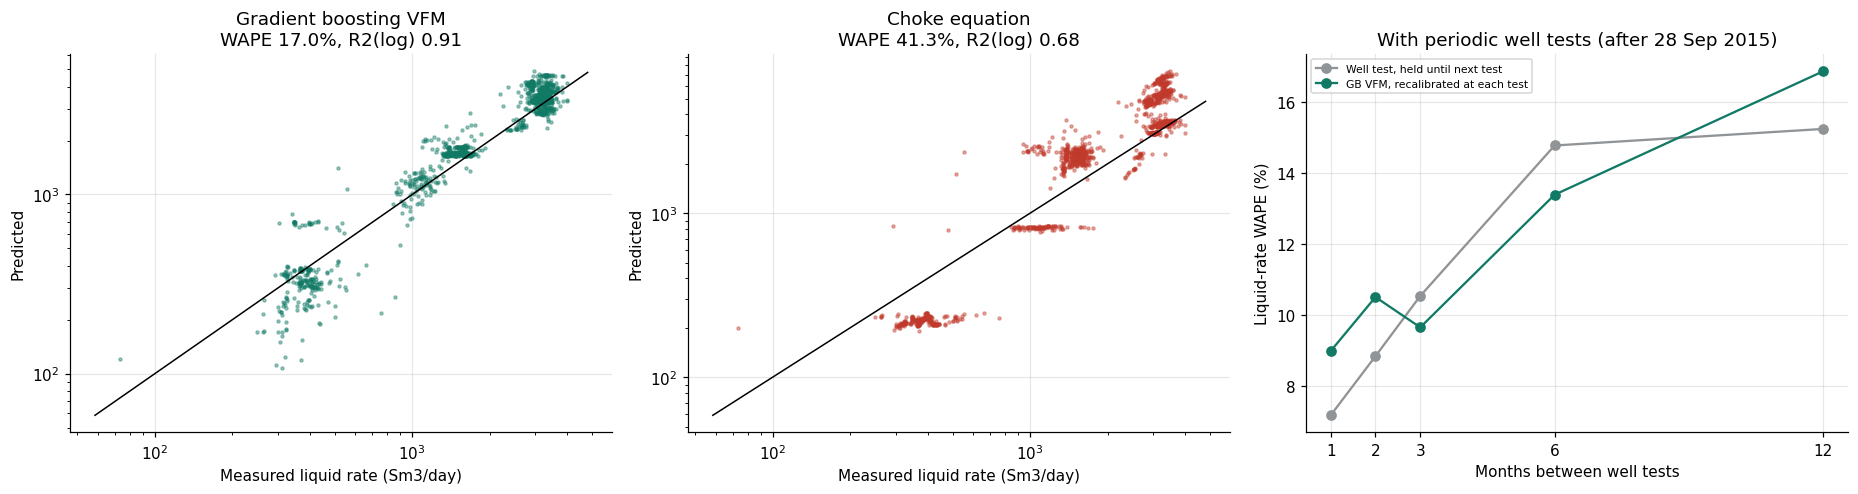

In [31]:
# K2. Chart: VFM accuracy, test period after 28 Sep 2015
d = VFM_PRED["liquid_rate"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (col, name, c) in zip(axes[:2], [("ml", "Gradient boosting VFM", "#117A65"), ("choke", "Choke equation", "#C0392B")]):
    ax.scatter(d["liquid_rate"], d[col], s=4, alpha=0.4, color=c)
    lim = [d["liquid_rate"].min() * 0.8, d["liquid_rate"].max() * 1.2]
    ax.plot(lim, lim, color="k", lw=1); ax.set_xscale("log"); ax.set_yscale("log")
    r = VFM_TBL.loc[("liquid_rate", "time split", name)]
    ax.set_title(f"{name}\nWAPE {r['WAPE %']:.1f}%, R2(log) {r['R2 (log)']:.2f}")
    ax.set_xlabel("Measured liquid rate (Sm3/day)"); ax.set_ylabel("Predicted")
axes[2].plot(SWEEP.index, SWEEP["Well test, held"], marker="o", color="#909497", label="Well test, held until next test")
axes[2].plot(SWEEP.index, SWEEP["GB VFM + recalibration"], marker="o", color="#117A65", label="GB VFM, recalibrated at each test")
axes[2].set_xticks(SWEEP.index); axes[2].set_xlabel("Months between well tests")
axes[2].set_ylabel("Liquid-rate WAPE (%)"); axes[2].set_title("With periodic well tests (after 28 Sep 2015)")
axes[2].legend(fontsize=7)
fig.tight_layout(); save(fig, "27_virtual_flow_meter.png"); plt.show()

## Step L: Event and anomaly detection (recommendation 1)

The system should flag unusual days automatically instead of relying on someone to spot them on a chart. Two complementary detectors:

1. VFM residual: a large gap between what the sensors say the well should flow and what was measured. Possible causes are a meter error, a sensor fault, or a real change in the well.
2. Isolation forest: an unsupervised model that flags sensor combinations unlike the well's normal operation, such as a frozen gauge or an unusual choke/pressure pairing.



In [32]:
# L1. Detectors
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import GroupKFold
an = vf.copy()
an["year"] = an["DATEPRD"].dt.year
# Out-of-fold VFM predictions (each year predicted by a model trained on the other years)
an["vfm_oof"] = np.nan
for tr_idx, te_idx in GroupKFold(n_splits=5).split(an, groups=an["year"]):
    m = gbm_vfm().fit(an.iloc[tr_idx][SENSORS], np.log(an.iloc[tr_idx]["liquid_rate"]))
    an.loc[an.index[te_idx], "vfm_oof"] = np.exp(m.predict(an.iloc[te_idx][SENSORS]))
an["resid"] = np.log(an["liquid_rate"]) - np.log(an["vfm_oof"])
roll_med = an.groupby("well")["resid"].transform(lambda s: s.rolling(60, min_periods=20, center=True).median())
roll_mad = an.groupby("well")["resid"].transform(lambda s: (s - s.rolling(60, min_periods=20, center=True).median())
                                                   .abs().rolling(60, min_periods=20, center=True).median())
an["resid_z"] = (an["resid"] - roll_med) / (1.4826 * roll_mad + 1e-6)
an["flag_vfm"] = an["resid_z"].abs() > 5
# Isolation forest per well on standardised sensors (NaN -> well median)
an["flag_if"] = False
for well, g in an.groupby("well"):
    Xs = g[SENSORS].fillna(g[SENSORS].median()).fillna(0)
    Xs = (Xs - Xs.mean()) / (Xs.std() + 1e-6)
    iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=0).fit(Xs)
    an.loc[g.index, "flag_if"] = iso.predict(Xs) == -1
flags = an.groupby("well")[["flag_vfm", "flag_if"]].sum().astype(int)
flags["days"] = an.groupby("well").size()
an[an["flag_vfm"] | an["flag_if"]][["well", "DATEPRD", "liquid_rate", "vfm_oof", "resid_z", "flag_vfm", "flag_if"]] \
    .to_csv(OUT / "part2_anomaly_flags.csv", index=False)
flags

,flag_vfm,flag_if,days
well,,,
15/9-F-1 C,5,5,413
15/9-F-11,14,11,1085
15/9-F-12,90,28,2728
15/9-F-14,103,27,2637
15/9-F-15 D,10,8,746


Saved figure: outputs/figures/28_anomalies.png


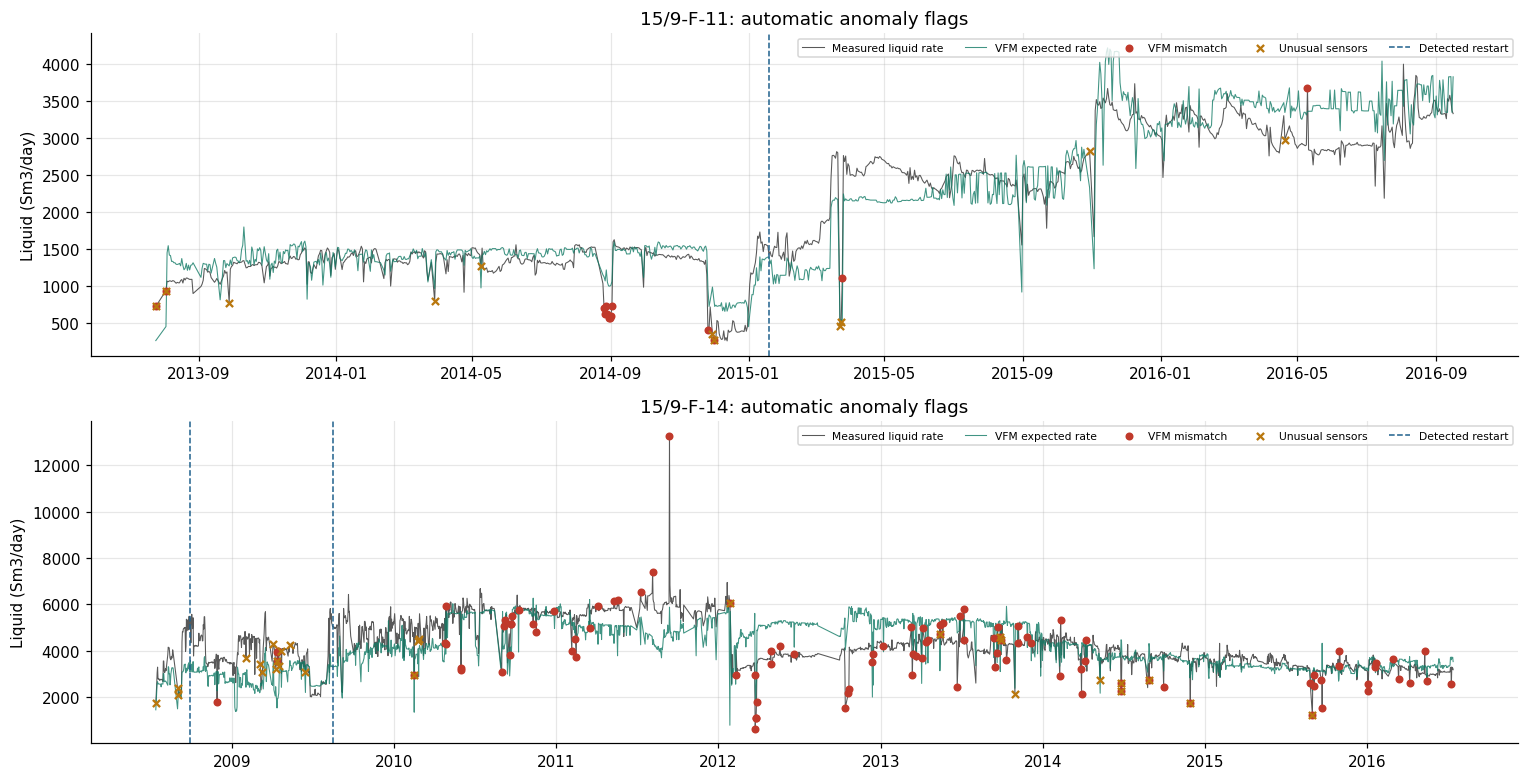

In [33]:
# L2. Chart: anomaly timeline for two wells
show = [w for w in ["15/9-F-11", "15/9-F-14"] if w in wells][:2]
fig, axes = plt.subplots(len(show), 1, figsize=(14, 3.6 * len(show)), squeeze=False)
for ax, well in zip(axes[:, 0], show):
    g = an[an["well"] == well]
    ax.plot(g["DATEPRD"], g["liquid_rate"], color="0.35", lw=0.7, label="Measured liquid rate")
    ax.plot(g["DATEPRD"], g["vfm_oof"], color="#117A65", lw=0.7, alpha=0.8, label="VFM expected rate")
    v = g[g["flag_vfm"]]; i_ = g[g["flag_if"]]
    ax.scatter(v["DATEPRD"], v["liquid_rate"], color="#C0392B", s=18, zorder=3, label="VFM mismatch")
    ax.scatter(i_["DATEPRD"], i_["liquid_rate"], marker="x", color="#B9770E", s=22, zorder=3, label="Unusual sensors")
    ev = weekly[(weekly["well"] == well) & weekly["event"]]["week"]
    for k, e in enumerate(ev):
        ax.axvline(e, color="#1F618D", ls="--", lw=1, label="Detected restart" if k == 0 else None)
    ax.set_title(f"{well}: automatic anomaly flags"); ax.set_ylabel("Liquid (Sm3/day)")
    ax.legend(fontsize=7, ncol=5, loc="upper right")
fig.tight_layout(); save(fig, "28_anomalies.png"); plt.show()

## Step M: Model Explainability (recommendation 6)

Engineers trust a model when they can see **what drives it** and that it behaves physically.
- Permutation importance: how much accuracy drops when each input is scrambled.
- Partial dependence: how the forecast responds as one input changes, all else held equal. The monotonic constraints should show here: forecasts never rise with horizon or with a faster-rising water cut.
- SHAP (optional): a per-forecast breakdown.

Saved figure: outputs/figures/29_explain_model.png


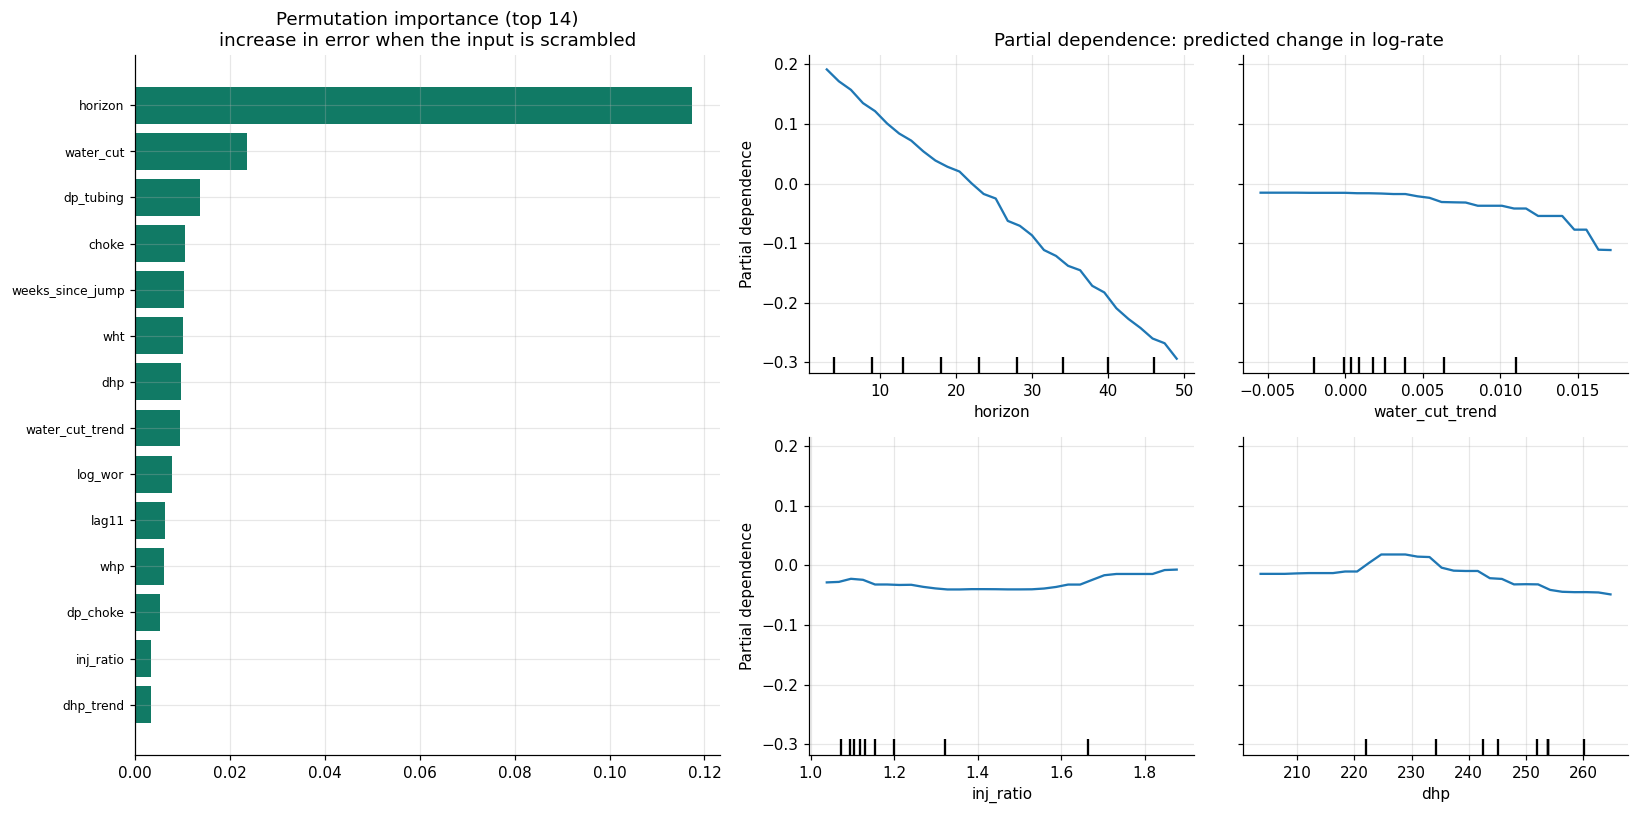

In [34]:
# M1. Permutation importance and partial dependence for the GB + physics P50 model (test forecast date)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
_, phys_models, X_tr = ml_forecast(TEST_ORIGIN, feats_physics, PHYS_COLS, "GB + physics (monotonic)", monotone=MONOTONE)
X_s, y_s, _ = training_table(TEST_ORIGIN, feats_physics, PHYS_COLS, stride=3)
X_s = X_s.astype(float)
sample = np.random.default_rng(0).choice(len(X_s), min(4000, len(X_s)), replace=False)
pi = permutation_importance(phys_models[1], X_s.iloc[sample], y_s[sample], n_repeats=5, random_state=0,
                            scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=X_s.columns).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].barh(imp.index[-14:], imp.values[-14:], color="#117A65")
axes[0].set_title("Permutation importance (top 14)\nincrease in error when the input is scrambled")
axes[0].tick_params(axis="y", labelsize=8)
PartialDependenceDisplay.from_estimator(phys_models[1], X_s.iloc[sample], ["horizon", "water_cut_trend", "inj_ratio", "dhp"],
                                        ax=axes[1], n_cols=2, grid_resolution=30)
axes[1].set_title("Partial dependence: predicted change in log-rate")
fig.tight_layout(); save(fig, "29_explain_model.png"); plt.show()

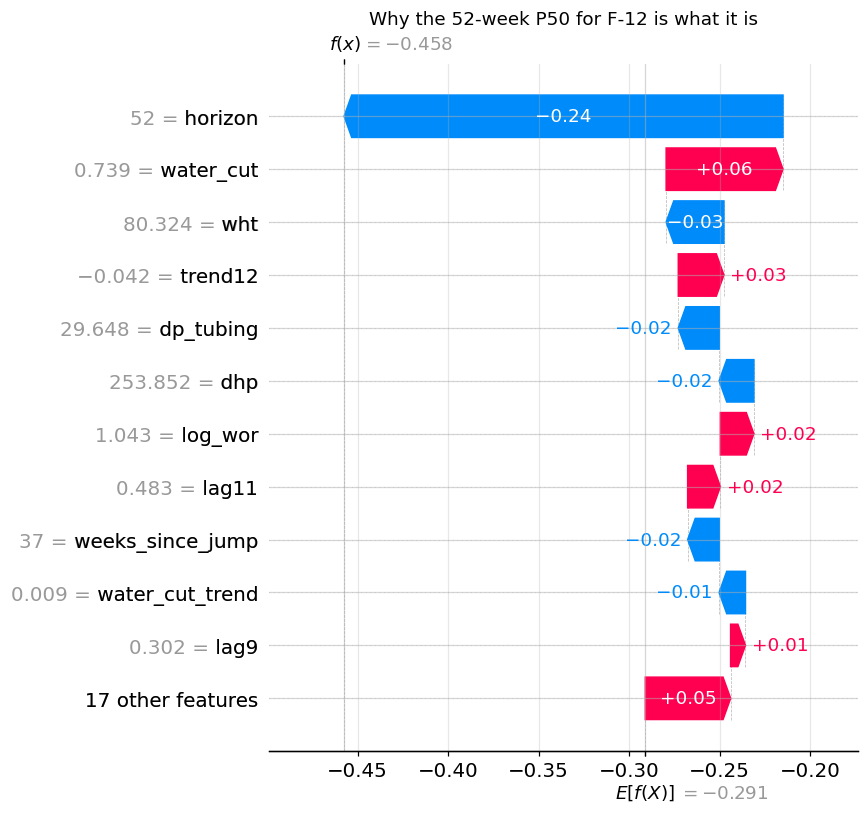

In [35]:
# M2. Optional SHAP explanation for one well's test forecast (skipped if shap isn't installed)
try:
    import shap
    a = ARRAYS["15/9-F-12"]; i0 = n_before(a, TEST_ORIGIN) - 1
    f, _ = feats_physics(a, i0)
    X_one = pd.DataFrame([f + [h] for h in (4, 13, 26, 52)], columns=X_tr.columns).astype(float)
    background = X_s.iloc[sample[:200]]
    explainer = shap.Explainer(phys_models[1].predict, background)
    sv = explainer(X_one)
    shap.plots.waterfall(sv[3], max_display=12, show=False)
    plt.title("Why the 52-week P50 for F-12 is what it is"); plt.tight_layout()
    plt.savefig(FIG / "30_shap_f12.png", dpi=140, bbox_inches="tight"); plt.show()
except ImportError:
    print("shap not installed - run  %pip install -q shap  in a cell above, then re-run this cell.")

## Step N: monthly retraining pipeline (recommendation 6)

A deployed model retrains on a schedule, keeps every version, and watches its own accuracy. This stage simulates that from **January 2015 to July 2016**, one run per month:

1. Train the chosen model on all data up to that month.
2. Save the model file, its forecast and its metadata to a versioned folder
3. One month later, score the previous run's 4-week forecast against what actually happened.
4. Check data drift: are recent inputs outside the range the model was trained on?



In [36]:
# N1. Monthly pipeline with a model registry
import joblib, json, base64, io
REG = OUT / "registry"; REG.mkdir(exist_ok=True)
PIPE_MODEL = "Arps + GB average"          # change to any method from the leaderboard

def pipeline_run(as_of):
    tag = pd.Timestamp(as_of).strftime("%Y-%m")                 # version = calendar month of the run
    as_of = pd.Timestamp(as_of).to_period("W-SUN").start_time
    arps = arps_forecast(as_of, n_boot=50)[0]
    gb, models, X = ml_forecast(as_of, feats_base, BASE_COLS, "Gradient boosting")
    fc = average_forecasts(arps, gb, PIPE_MODEL) if PIPE_MODEL == "Arps + GB average" else gb
    d = REG / tag; d.mkdir(exist_ok=True)
    joblib.dump(models, d / "gb_models.joblib")
    fc.to_csv(d / "forecast.csv", index=False)
    lo_, hi_ = X.quantile(0.01), X.quantile(0.99)
    meta = {"version": tag, "trained_on_data_before": str(as_of.date()), "model": PIPE_MODEL,
            "training_rows": int(len(X)), "wells": sorted(fc["well"].unique().tolist())}
    (d / "meta.json").write_text(json.dumps(meta, indent=2))
    return tag, fc, (lo_, hi_)

REGISTRY, prev = [], None
for as_of in pd.date_range("2015-01-01", "2016-07-01", freq="MS"):
    tag, fc, rng_ = pipeline_run(as_of)
    row = {"version": tag, "as_of": as_of.date()}
    # Score the previous run's first 4 weeks now that the actuals are in
    if prev is not None:
        p4 = prev[(prev["h"] <= 4) & prev["actual"].notna()]
        if len(p4):
            row["prev_4wk_volume_err_%"] = (p4["p50"].sum() - p4["actual"].sum()) / p4["actual"].sum() * 100
    # Drift: share of current inputs outside the training 1-99% range
    cur = []
    for well, a in ARRAYS.items():
        i0 = n_before(a, pd.Timestamp(as_of).to_period("W-SUN").start_time) - 1
        if i0 >= LAGS - 1:
            cur.append(feats_base(a, i0)[0] + [1])
    cur = pd.DataFrame(cur, columns=list(rng_[0].index))
    row["drift_%_inputs_out_of_range"] = float(((cur < rng_[0]) | (cur > rng_[1])).mean().mean() * 100)
    REGISTRY.append(row); prev = fc
    print(f"run {tag}: saved to outputs/registry/{tag}/")
REGISTRY = pd.DataFrame(REGISTRY)
REGISTRY.to_csv(REG / "registry.csv", index=False)
REGISTRY.round(1)

run 2015-01: saved to outputs/registry/2015-01/
run 2015-02: saved to outputs/registry/2015-02/
run 2015-03: saved to outputs/registry/2015-03/
run 2015-04: saved to outputs/registry/2015-04/
run 2015-05: saved to outputs/registry/2015-05/
run 2015-06: saved to outputs/registry/2015-06/
run 2015-07: saved to outputs/registry/2015-07/
run 2015-08: saved to outputs/registry/2015-08/
run 2015-09: saved to outputs/registry/2015-09/
run 2015-10: saved to outputs/registry/2015-10/
run 2015-11: saved to outputs/registry/2015-11/
run 2015-12: saved to outputs/registry/2015-12/
run 2016-01: saved to outputs/registry/2016-01/
run 2016-02: saved to outputs/registry/2016-02/
run 2016-03: saved to outputs/registry/2016-03/
run 2016-04: saved to outputs/registry/2016-04/
run 2016-05: saved to outputs/registry/2016-05/
run 2016-06: saved to outputs/registry/2016-06/
run 2016-07: saved to outputs/registry/2016-07/


,version,as_of,drift_%_inputs_out_of_range,prev_4wk_volume_err_%
0,2015-01,2015-01-01,30.0,NaN
1,2015-02,2015-02-01,22.0,-49.6
2,2015-03,2015-03-01,11.0,-23.3
3,2015-04,2015-04-01,7.0,-27.6
4,2015-05,2015-05-01,7.0,-22.2
5,2015-06,2015-06-01,2.0,-11.7
6,2015-07,2015-07-01,8.0,0.4
7,2015-08,2015-08-01,6.0,0.4
8,2015-09,2015-09-01,16.0,4.9
9,2015-10,2015-10-01,3.0,6.3


Saved figure: outputs/figures/31_monitoring.png


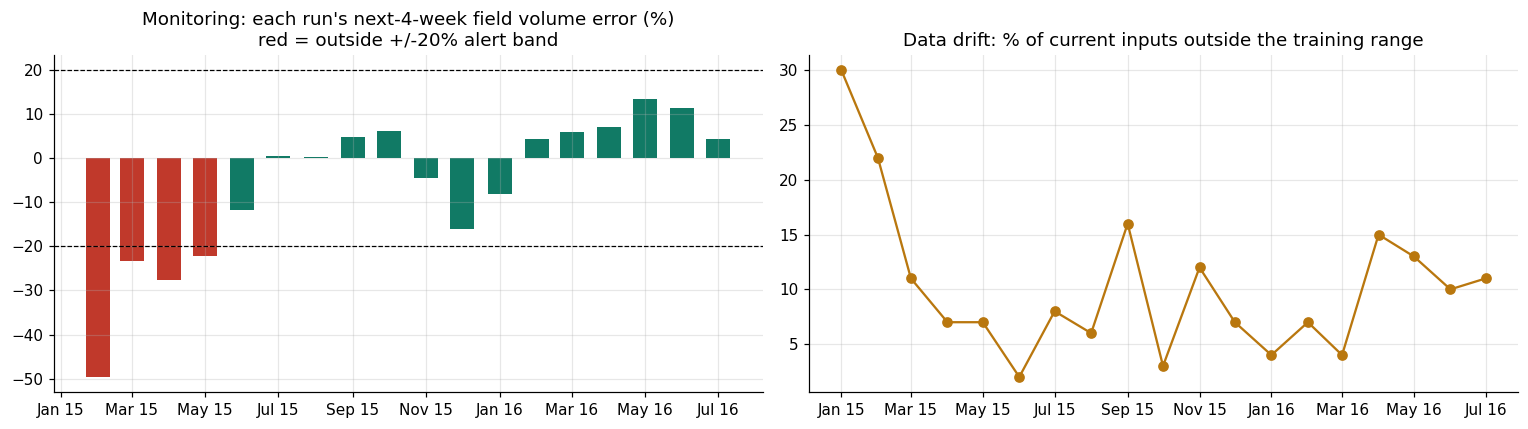

Dashboard written to outputs/dashboard.html. Download it from Drive and open it in a browser.


In [37]:
# N2. Chart: model monitoring, plus a one-page HTML dashboard
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
r = REGISTRY.dropna(subset=["prev_4wk_volume_err_%"])
axes[0].bar(pd.to_datetime(r["as_of"]), r["prev_4wk_volume_err_%"], width=20,
            color=np.where(r["prev_4wk_volume_err_%"].abs() > 20, "#C0392B", "#117A65"))
axes[0].axhline(20, color="k", ls="--", lw=0.8); axes[0].axhline(-20, color="k", ls="--", lw=0.8)
axes[0].set_title("Monitoring: each run's next-4-week field volume error (%)\nred = outside +/-20% alert band")
axes[1].plot(pd.to_datetime(REGISTRY["as_of"]), REGISTRY["drift_%_inputs_out_of_range"], marker="o", color="#B9770E")
axes[1].set_title("Data drift: % of current inputs outside the training range")
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.tight_layout(); save(fig, "31_monitoring.png"); plt.show()

def img64(path):
    return base64.b64encode(Path(path).read_bytes()).decode()
latest = REGISTRY.iloc[-1]["version"]
fc_latest = pd.read_csv(REG / latest / "forecast.csv", parse_dates=["week"])
summary_html = (fc_latest.groupby("well").agg(first_week=("week", "min"), weeks=("week", "size"),
                                              p50_next_4wk=("p50", lambda s: s.iloc[:4].mean()))
                .assign(p50_next_4wk=lambda t: t["p50_next_4wk"].round(0)).to_html())
html = f'''<html><head><meta charset="utf-8"><title>Volve forecast dashboard</title>
<style>body{{font-family:Arial,sans-serif;max-width:1100px;margin:24px auto;color:#1b2420}}
img{{max-width:100%;border:1px solid #ddd;margin:8px 0}}table{{border-collapse:collapse}}td,th{{border:1px solid #ccc;padding:4px 8px}}</style></head>
<body><h1>Volve production forecast dashboard</h1>
<p>Latest model version: <b>{latest}</b> ({PIPE_MODEL}). Data up to {REGISTRY.iloc[-1]["as_of"]}.</p>
<h2>Leaderboard (rolling backtest)</h2>{LEADERBOARD.round(2).to_html()}
<h2>Latest forecast, average P50 for the next 4 weeks (Sm3/day)</h2>{summary_html}
<h2>Monitoring</h2><img src="data:image/png;base64,{img64(FIG / '31_monitoring.png')}">
<h2>Model comparison</h2><img src="data:image/png;base64,{img64(FIG / '21_part2_leaderboard.png')}">
<h2>Virtual flow meter</h2><img src="data:image/png;base64,{img64(FIG / '27_virtual_flow_meter.png')}">
</body></html>'''
(OUT / "dashboard.html").write_text(html)
print("Dashboard written to outputs/dashboard.html. Download it from Drive and open it in a browser.")